# Topic 09 (N019), SEDBM 2026 — "Necessary but Not Sufficient?" Necessary Condition Analysis
This notebook reruns the whole conference analysis and writes the manuscript outputs:

| Output | File |
|---|---|
| Tables 1–6, Figures 1–4 and S1 (APA 7) | `SEDBM_NCA_N019_Results_Tables_Figures.docx` |
| Figures | `figures/` — PNG 300 dpi, TIFF 600 dpi, PDF |
| Every number behind the tables | `output/*.csv` |

**Runtime:** default Python 3 runtime. NCA runs in Python; the confirmatory factor analysis for Table 2 runs in R (lavaan).
**How to run:** Runtime → Run all. About 15–20 minutes, most of it installing R packages.

## Step 0 — Settings

In [1]:
B_PERM  = 10000    # permutation-test replications for the NCA effect sizes (Table 3)
SEED    = 2026
LONGSTR = 20       # careless responding: same answer on >= this many consecutive items (of 34)
DATA_ID = "1_9cn-z6Ua52PLwcybEq6r5949gIg_FKg"   # Google Drive id of the N19 dataset CSV
DATA_FILE = "N19.csv"

import os
os.makedirs("output", exist_ok=True); os.makedirs("figures", exist_ok=True)
with open("settings.R", "w") as f:
    f.write(f'B_BOOT <- 100; B_COMP <- 100; SESOI <- 0.1; LONGSTR <- {LONGSTR}; SEED <- {SEED}; DATA_FILE <- "{DATA_FILE}"\n')
print("Settings saved.")

Settings saved.


## Step 1 — Install tools (2–5 minutes, once per session)

In [2]:
!which Rscript > /dev/null || (apt-get -qq update && apt-get -qq install -y r-base > /dev/null)
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1 || true
!pip -q install python-docx statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 22.0 MB/s eta 0:00:00


In [3]:
%%writefile install.R
pk   <- c("lavaan", "semTools", "sandwich", "lmtest")
need <- pk[!sapply(pk, requireNamespace, quietly = TRUE)]
if (length(need)) {
  codename <- tryCatch(system("lsb_release -cs", intern = TRUE), error = function(e) "jammy")
  options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
          paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])))
  try(install.packages(need, repos = sprintf("https://packagemanager.posit.co/cran/__linux__/%s/latest", codename), Ncpus = 2, quiet = TRUE))
  still <- need[!sapply(need, requireNamespace, quietly = TRUE)]
  if (length(still)) install.packages(still, repos = "https://cloud.r-project.org", Ncpus = 2, quiet = TRUE)
}
for (p in pk) cat(p, as.character(packageVersion(p)), "\n")

Writing install.R


In [4]:
!Rscript install.R
import matplotlib.font_manager as fm; fm._load_fontmanager(try_read_cache=False)

also installing the dependencies ‘mnormt’, ‘pbivnorm’, ‘numDeriv’, ‘quadprog’, ‘zoo’

lavaan 0.7.3 
semTools 0.5.10 
sandwich 3.1.3 
lmtest 0.9.40 


## Step 2 — Load the data\nDownloads the CSV from the shared Drive link. If that fails, upload the CSV with the folder icon on the left and name it `N19.csv`.

In [5]:
import urllib.request, pandas as pd
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(f"https://drive.google.com/uc?export=download&id={DATA_ID}", DATA_FILE)
raw = pd.read_csv(DATA_FILE)
print(f"{raw.shape[0]} rows, {raw.shape[1]} columns")
assert raw.shape == (345, 44), "Unexpected file: expected 345 rows and 44 columns"

345 rows, 44 columns


## Step 3 — Measurement quality (Table 2)\nNine-factor confirmatory factor analysis in R (lavaan): loadings, α, CR and AVE.

In [6]:
%%writefile prep.R
# ---- prep.R: settings, packages, data, coding, screening (sourced by every analysis script) ----
source("settings.R")
suppressPackageStartupMessages({ library(lavaan); library(semTools); library(sandwich); library(lmtest) })
dir.create("output", showWarnings = FALSE)

raw <- read.csv(DATA_FILE, check.names = FALSE, stringsAsFactors = FALSE, fileEncoding = "UTF-8")
stopifnot(ncol(raw) == 44)
codes <- c(paste0("GD", 1:4), paste0("GP", 1:4), paste0("IEM", 1:4), paste0("MP", 1:4), paste0("FP", 1:3),
           paste0("LQ", 1:3), paste0("JIT", 1:4), paste0("TPM", 1:4), paste0("CSR", 1:4))
d0 <- raw
names(d0)[1:10]  <- c("timestamp", "consent", "age", "edu", "gender", "industry", "tot_exp", "org_exp", "position", "size")
names(d0)[11:44] <- codes
d0[codes] <- lapply(d0[codes], as.numeric)

dims <- list(GD = codes[1:4], GP = codes[5:8], IEM = codes[9:12], MP = codes[13:16], FP = codes[17:19],
             LQ = codes[20:22], JIT = codes[23:26], TPM = codes[27:30], CSR = codes[31:34])
dims$GSCM <- c(dims$GD, dims$GP, dims$IEM); dims$LEAN <- c(dims$LQ, dims$JIT, dims$TPM); dims$PERF <- c(dims$MP, dims$FP)
for (k in names(dims)) d0[[k]] <- rowMeans(d0[dims[[k]]])

# screening (uses the original industry labels)
longstring  <- function(x) max(rle(as.numeric(x))$lengths)
d0$consent_ok <- d0$consent == "Agree"
d0$sd_items   <- apply(d0[codes], 1, sd)
d0$longstring <- apply(d0[codes], 1, longstring)
d0$careless   <- d0$sd_items == 0 | d0$longstring >= LONGSTR
d0$dup        <- duplicated(d0[c("age", "edu", "gender", "industry", "tot_exp", "org_exp", "position", "size", codes)])
mah           <- mahalanobis(d0[codes], colMeans(d0[codes]), cov(d0[codes]))
d0$mah_out    <- pchisq(mah, df = length(codes), lower.tail = FALSE) < .001

# controls: industries with < 20 consenting respondents merged into "Other"
d0$industry_raw <- d0$industry
small <- names(which(table(d0$industry[d0$consent_ok]) < 20))
d0$industry[d0$industry %in% small] <- "Other"
d0$size     <- relevel(factor(d0$size), ref = "More than 249")
d0$industry <- relevel(factor(d0$industry), ref = "Other")
d0$position <- relevel(factor(d0$position), ref = "Lower Manger")

full  <- subset(d0, consent_ok)
clean <- subset(d0, consent_ok & !careless & !dup)

# shared helpers and model strings
z_df <- function(d) { v <- c("GSCM", "LEAN", "CSR", "MP", "FP", "PERF"); d[paste0("z", v)] <- scale(d[v]); d }
add_dummies <- function(d) { mm <- model.matrix(~ size + industry + position, d)[, -1, drop = FALSE]
  colnames(mm) <- make.names(colnames(mm)); cbind(d, mm) }
ctrl_names <- setdiff(colnames(add_dummies(full)), colnames(full))
m_first  <- paste(sapply(names(dims)[1:9], function(k) paste(k, "=~", paste(dims[[k]], collapse = " + "))), collapse = "\n")
fitcfa   <- function(model, d) cfa(model, data = d[codes], estimator = "MLR")

Writing prep.R


In [7]:
%%writefile c_common.R
# ---- c_common.R: shared model pieces for the conference reanalysis ----
source("prep.R")
all345 <- d0
samples <- list(`All 345` = all345, `Consented 342` = full, `Clean 262` = clean)
prep_d <- function(d) { d$size_n <- as.numeric(factor(as.character(d$size), levels = c("6 - 49", "50 - 249", "More than 249")))
  d$ind_n <- as.numeric(factor(d$industry_raw)); d }
meas <- function(csr4 = TRUE, lean = TRUE) {
  x <- c('GD =~ GD1 + GD2 + GD3 + GD4', 'GP =~ GP1 + GP2 + GP3 + GP4', 'IEM =~ IEM1 + IEM2 + IEM3 + IEM4',
         if (lean) c('LQ =~ LQ1 + LQ2 + LQ3', 'JIT =~ JIT1 + JIT2 + JIT3 + JIT4', 'TPM =~ TPM1 + TPM2 + TPM3 + TPM4'),
         'MP =~ MP1 + MP2 + MP3 + MP4', 'FP =~ FP1 + FP2 + FP3',
         if (csr4) 'CSR =~ CSR1 + CSR2 + CSR3 + CSR4' else 'CSR =~ CSR1 + CSR2 + CSR3',
         'GSCM =~ GD + GP + IEM', if (lean) 'LM =~ LQ + JIT + TPM', 'BP =~ MP + FP')
  paste(x, collapse = "\n") }
struct <- list(
  `Parallel (published)` = 'LM ~ GSCM\nCSR ~ GSCM\nBP ~ GSCM + LM + CSR',
  `Parallel + LM~~CSR` = 'LM ~ GSCM\nCSR ~ GSCM\nBP ~ GSCM + LM + CSR\nLM ~~ CSR',
  `CSR only` = 'CSR ~ GSCM\nBP ~ GSCM + CSR',
  `Serial GSCM-LM-CSR` = 'LM ~ GSCM\nCSR ~ GSCM + LM\nBP ~ GSCM + LM + CSR',
  `Serial GSCM-CSR-LM` = 'CSR ~ GSCM\nLM ~ GSCM + CSR\nBP ~ GSCM + LM + CSR')
build_model <- function(st, csr4 = TRUE, ctl = TRUE) {
  mod <- paste(meas(csr4, lean = st != "CSR only"), struct[[st]], sep = "\n")
  if (ctl) mod <- paste(sub("BP ~ GSCM", "BP ~ size_n + ind_n + GSCM", mod), "size_n ~~ ind_n", sep = "\n")
  mod }
fit_admissible <- function(mod, d) {   # refit with equal BP loadings if the solution is inadmissible
  vars <- c(codes, "size_n", "ind_n"); f <- sem(mod, data = d[vars], estimator = "ML"); fix <- FALSE
  if (!isTRUE(suppressWarnings(tryCatch(lavInspect(f, "post.check"), error = function(e) FALSE)))) {
    f <- sem(sub("BP =~ MP + FP", "BP =~ b*MP + b*FP", mod, fixed = TRUE), data = d[vars], estimator = "ML"); fix <- TRUE }
  attr(f, "bp_fix") <- fix; f }
key_est <- function(f) {   # standardized quantities reported throughout
  ss <- standardizedSolution(f, se = FALSE); g <- function(l, r) { v <- ss$est.std[ss$lhs == l & ss$rhs == r & ss$op == "~"]; if (length(v)) v else NA }
  lv <- lavInspect(f, "cor.lv"); has_lm <- "LM" %in% rownames(lv)
  c(GSCM_LM = g("LM", "GSCM"), GSCM_CSR = g("CSR", "GSCM"), LM_BP = g("BP", "LM"), CSR_BP = g("BP", "CSR"), GSCM_BP = g("BP", "GSCM"),
    ind_LM = g("LM", "GSCM") * g("BP", "LM"), ind_CSR = g("CSR", "GSCM") * g("BP", "CSR"),
    r_LM_CSR = if (has_lm) lv["LM", "CSR"] else NA) }

Writing c_common.R


In [8]:
%%writefile c_measure.R
# ---- c_measure.R: measurement quality, all 345 respondents (Table 2) ----
source("c_common.R")
first <- paste(sapply(names(dims)[1:9], function(k) paste(k, "=~", paste(dims[[k]], collapse = " + "))), collapse = "\n")
out <- list()
for (sn in names(samples)) {
  d <- samples[[sn]]; f <- cfa(first, data = d[codes], estimator = "MLR"); ss <- standardizedSolution(f); l <- ss[ss$op == "=~", ]
  fm <- fitMeasures(f, c("chisq.scaled", "df.scaled", "cfi.robust", "tli.robust", "rmsea.robust", "srmr"))
  for (k in names(dims)[1:9]) { lam <- l$est.std[l$lhs == k]; th <- 1 - lam^2
    a <- psych_alpha <- { x <- d[dims[[k]]]; kk <- ncol(x); kk / (kk - 1) * (1 - sum(apply(x, 2, var)) / var(rowSums(x))) }
    out[[length(out) + 1]] <- data.frame(Sample = sn, Construct = k, Items = length(lam), Loading_min = round(min(lam), 3), Loading_max = round(max(lam), 3),
      Alpha = round(a, 3), CR = round(sum(lam)^2 / (sum(lam)^2 + sum(th)), 3), AVE = round(mean(lam^2), 3),
      chisq = round(fm[[1]], 1), df = fm[[2]], cfi = round(fm[[3]], 3), tli = round(fm[[4]], 3), rmsea = round(fm[[5]], 3), srmr = round(fm[[6]], 3)) }
}
o <- do.call(rbind, out); write.csv(o, "output/C_T2_measurement.csv", row.names = FALSE); print(o[o$Sample == "All 345", ], row.names = FALSE)
cat("\nMEASURE DONE\n")

Writing c_measure.R


In [9]:
!Rscript c_measure.R

  Sample Construct Items Loading_min Loading_max Alpha    CR   AVE chisq  df
 All 345        GD     4       0.813       0.853 0.897 0.898 0.687 686.6 491
 All 345        GP     4       0.836       0.873 0.915 0.915 0.730 686.6 491
 All 345       IEM     4       0.822       0.890 0.918 0.917 0.735 686.6 491
 All 345        MP     4       0.801       0.871 0.902 0.902 0.697 686.6 491
 All 345        FP     3       0.834       0.873 0.885 0.885 0.719 686.6 491
 All 345        LQ     3       0.797       0.830 0.856 0.858 0.669 686.6 491
 All 345       JIT     4       0.745       0.836 0.858 0.859 0.604 686.6 491
 All 345       TPM     4       0.833       0.852 0.908 0.908 0.713 686.6 491
 All 345       CSR     4       0.820       0.857 0.899 0.900 0.692 686.6 491
  cfi   tli rmsea  srmr
 0.97 0.966 0.043 0.029
 0.97 0.966 0.043 0.029
 0.97 0.966 0.043 0.029
 0.97 0.966 0.043 0.029
 0.97 0.966 0.043 0.029
 0.97 0.966 0.043 0.029
 0.97 0.966 0.043 0.029
 0.97 0.966 0.043 0.029
 0.97 0.966 0.

## Step 4 — Necessary Condition Analysis (Tables 1, 3–6; Figure 4 data)\nCE-FDH and CR-FDH ceilings, effect sizes and permutation tests for the three bundles and six dimensions; bottleneck table with CR-FDH and clean-sample sensitivity; robustness; leave-one-out for every ceiling-defining case; the regression contrast with the GSCM × lean interaction; the necessity–sufficiency map; and the sample flow. About 1–5 minutes with 10,000 permutations.

In [10]:
# ---- nca_analysis.py: Necessary Condition Analysis of GSCM, lean and CSR for business performance ----
# Ceiling envelopment (CE-FDH) and ceiling regression (CR-FDH), effect size d, permutation test (Dul, 2016; Dul et al., 2020)
import warnings; warnings.filterwarnings("ignore")
import itertools, os, numpy as np, pandas as pd
try:
    import statsmodels.formula.api as smf
except ImportError:
    smf = None
for _k, _v in {"B_PERM": 10000, "SEED": 2026, "LONGSTR": 20, "DATA_FILE": "N19.csv"}.items(): globals().setdefault(_k, _v)
os.makedirs("output", exist_ok=True)

codes = [f"GD{i}" for i in range(1, 5)] + [f"GP{i}" for i in range(1, 5)] + [f"IEM{i}" for i in range(1, 5)] + [f"MP{i}" for i in range(1, 5)] + \
        [f"FP{i}" for i in range(1, 4)] + [f"LQ{i}" for i in range(1, 4)] + [f"JIT{i}" for i in range(1, 5)] + [f"TPM{i}" for i in range(1, 5)] + [f"CSR{i}" for i in range(1, 5)]
raw = pd.read_csv(DATA_FILE)
raw.columns = ["timestamp", "consent", "age", "edu", "gender", "industry", "tot_exp", "org_exp", "position", "size"] + codes
d0 = raw.copy(); d0["case"] = np.arange(1, len(d0) + 1)          # case number = row in the public file
items = d0[codes].astype(float)
d0["sd_items"] = items.std(axis=1)
d0["longstring"] = items.apply(lambda r: max(len(list(g)) for _, g in itertools.groupby(r)), axis=1)
d0["careless"] = (d0.sd_items == 0) | (d0.longstring >= LONGSTR)
d0["dup"] = d0.duplicated(subset=["age", "edu", "gender", "industry", "tot_exp", "org_exp", "position", "size"] + codes)
GRP = {"GD": codes[0:4], "GP": codes[4:8], "IEM": codes[8:12], "LQ": codes[19:22], "JIT": codes[22:26], "TPM": codes[26:30], "CSR": codes[30:34],
       "GSCM": codes[0:12], "LEAN": codes[19:30], "PERF": codes[12:19]}
for k, v in GRP.items(): d0[k] = d0[v].astype(float).mean(axis=1)
full = d0[d0.consent == "Agree"].copy(); clean = full[~full.careless & ~full.dup].copy()
SAMPLES = {"Full (n = 342)": full, "Clean (n = 262)": clean, "All 345": d0}
MAIN = ["GSCM", "LEAN", "CSR"]; DIMS = ["GD", "GP", "IEM", "LQ", "JIT", "TPM"]; Y = "PERF"

# ---------- NCA core ----------
def ce_step(x, y):
    """CE-FDH ceiling: for each unique x, the highest y among cases with x_i <= x."""
    o = np.argsort(x, kind="mergesort"); xs, ys = x[o], y[o]
    ux, last = np.unique(xs, return_index=False), None
    cm = np.maximum.accumulate(ys); idx = np.searchsorted(xs, np.unique(xs), side="right") - 1
    return np.unique(xs), cm[idx]
def scope(x, y): return x.min(), x.max(), y.min(), y.max()
def d_ce(x, y):
    ux, c = ce_step(x, y); x0, x1, y0, y1 = scope(x, y)
    if x1 == x0 or y1 == y0: return 0.0
    area = np.sum((y1 - c[:-1]) * np.diff(ux)); return area / ((x1 - x0) * (y1 - y0))
def peers(x, y):
    """Upper-left corner points of the CE-FDH step function."""
    ux, c = ce_step(x, y); keep = np.r_[True, np.diff(c) > 0]; return ux[keep], c[keep]
def cr_line(x, y):
    px, py = peers(x, y)
    if len(px) < 2: return 0.0, py[0]
    b, a = np.polyfit(px, py, 1); return b, a
def d_cr(x, y, grid=4001):
    b, a = cr_line(x, y); x0, x1, y0, y1 = scope(x, y)
    xx = np.linspace(x0, x1, grid); c = np.clip(a + b * xx, y0, y1)
    area = (np.trapezoid if hasattr(np, "trapezoid") else np.trapz)(y1 - c, xx); return area / ((x1 - x0) * (y1 - y0))
def accuracy_cr(x, y):
    b, a = cr_line(x, y); return np.mean(y <= a + b * x + 1e-9)
def perm_p(x, y, f, B, rng):
    obs = f(x, y); null = np.array([f(x, rng.permutation(y)) for _ in range(B)])
    return obs, (np.sum(null >= obs - 1e-12) + 1) / (B + 1)
def size_label(dv): return "small" if dv < .1 else "medium" if dv < .3 else "large" if dv < .5 else "very large"
def required_ce(x, y, ylev):
    """Minimum x needed for outcome level ylev (CE-FDH): smallest x among cases reaching ylev."""
    m = y >= ylev - 1e-9; return x[m].min() if m.any() else np.nan
def required_cr(x, y, ylev):
    b, a = cr_line(x, y); x0, x1, y0, y1 = scope(x, y)
    if b <= 0: return x0
    return float(np.clip((ylev - a) / b, x0, x1))

rng = np.random.default_rng(SEED)
# ---------- Table 3: effect sizes and permutation tests ----------
rows = []
for sname in ["Full (n = 342)", "Clean (n = 262)"]:
    dd = SAMPLES[sname]; y = dd[Y].values
    for X in MAIN + DIMS:
        x = dd[X].values
        dce, pce = perm_p(x, y, d_ce, B_PERM, rng); dcr, pcr = perm_p(x, y, d_cr, B_PERM, rng)
        rows.append(dict(Sample=sname, Condition=X, n=len(dd), d_CE=round(dce, 3), p_CE=round(pce, 4), d_CR=round(dcr, 3), p_CR=round(pcr, 4),
                         accuracy_CR=round(100 * accuracy_cr(x, y), 1), size_CE=size_label(dce), necessary=(dce >= .1) and (pce < .05)))
    print(sname, "done")
t3 = pd.DataFrame(rows); t3.to_csv("output/N_T3_effect_sizes.csv", index=False); print(t3.to_string(index=False))

# ---------- Outlier analysis: influence of single cases on d (CE-FDH) ----------
orows = []
for X in MAIN:
    dd = full; x, y = dd[X].values, dd[Y].values; base = d_ce(x, y)
    infl = []
    for i in range(len(dd)):
        m = np.ones(len(dd), bool); m[i] = False; infl.append(d_ce(x[m], y[m]) - base)
    infl = np.array(infl); top = np.argsort(-np.abs(infl))[:3]
    for r_, i in enumerate(top):
        orows.append(dict(Condition=X, rank=r_ + 1, case=int(dd.case.iloc[i]), x=round(x[i], 2), PERF=round(y[i], 2), d_with=round(base, 3),
                          d_without=round(base + infl[i], 3), change=round(infl[i], 3), careless=bool(dd.careless.iloc[i])))
to = pd.DataFrame(orows); to.to_csv("output/N_X1_outliers.csv", index=False); print(to.to_string(index=False))

# ---------- Table 5: robustness ----------
OUT_CASE = int(to[(to.Condition == "CSR") & (to["rank"] == 1)].case.iloc[0])
rrows = []
specs = [("Main: full sample, CE-FDH", full, "ce"), ("Full sample, CR-FDH", full, "cr"), ("Clean sample (careless responses removed)", clean, "ce"),
         ("All 345 responses", d0, "ce"), (f"Full sample without case {OUT_CASE}", full[full.case != OUT_CASE], "ce")]
for lab, dd, ceil in specs:
    rec = dict(Specification=lab, n=len(dd))
    for X in MAIN:
        f = d_ce if ceil == "ce" else d_cr; dv, pv = perm_p(dd[X].values, dd[Y].values, f, 2000, rng)
        rec[f"{X}_d"] = round(dv, 3); rec[f"{X}_p"] = round(pv, 4)
    rrows.append(rec)
t5 = pd.DataFrame(rrows); t5.to_csv("output/N_T5_robustness.csv", index=False); print(t5.to_string(index=False))

# ---------- Table 4: bottleneck table (actual scale values, 1-5) ----------
levels = [3.0, 3.5, 4.0, 4.5, 5.0]; brows = []
for lev in levels:
    rec = dict(PERF_level=lev)
    for X in MAIN:
        x, y = full[X].values, full[Y].values; req = required_ce(x, y, lev)
        rec[f"{X}_required"] = round(req, 2); rec[f"{X}_share_below"] = round(100 * np.mean(x < req - 1e-9), 1)
        rec[f"{X}_required_noOut"] = round(required_ce(full[full.case != OUT_CASE][X].values, full[full.case != OUT_CASE][Y].values, lev), 2)
        rec[f"{X}_required_CR"] = round(required_cr(x, y, lev), 2)
        rec[f"{X}_required_clean"] = round(required_ce(clean[X].values, clean[Y].values, lev), 2)
    rec["share_reaching"] = round(100 * np.mean(full[Y].values >= lev - 1e-9), 1)
    rec["n_reaching"] = int(np.sum(full[Y].values >= lev - 1e-9)); rec["n_reaching_clean"] = int(np.sum(clean[Y].values >= lev - 1e-9))
    brows.append(rec)
t4 = pd.DataFrame(brows); t4.to_csv("output/N_T4_bottleneck.csv", index=False); print(t4.to_string(index=False))

# ---------- Table 6: sufficiency (OLS) vs necessity ----------
if smf is not None:
    z = full.copy()
    for v in MAIN + [Y]: z["z" + v] = (z[v] - z[v].mean()) / z[v].std()
    small = z.industry.value_counts()[lambda s: s < 20].index; z.loc[z.industry.isin(small), "industry"] = "Other"
    m = smf.ols("zPERF ~ zGSCM + zLEAN + zCSR + C(size) + C(industry) + C(position)", z).fit(cov_type="HC3")
    t6 = pd.DataFrame([dict(Condition=X, beta=round(m.params["z" + X], 3), se=round(m.bse["z" + X], 3), p=round(m.pvalues["z" + X], 4),
                            ci_low=round(m.conf_int().loc["z" + X, 0], 3), ci_high=round(m.conf_int().loc["z" + X, 1], 3),
                            d_CE=t3[(t3.Sample == "Full (n = 342)") & (t3.Condition == X)].d_CE.iloc[0],
                            p_CE=t3[(t3.Sample == "Full (n = 342)") & (t3.Condition == X)].p_CE.iloc[0]) for X in MAIN])
    t6["R2"] = round(m.rsquared, 3); t6.to_csv("output/N_T6_sufficiency_necessity.csv", index=False); print(t6.to_string(index=False))

    # Interaction test for complementarity (Proposition 2): is the joint effect of GSCM and lean additive or multiplicative?
    mi = smf.ols("zPERF ~ zGSCM * zLEAN + zCSR + C(size) + C(industry) + C(position)", z).fit(cov_type="HC3")
    t6i = pd.DataFrame([dict(Term=k, beta=round(mi.params[k], 3), se=round(mi.bse[k], 3), p=round(mi.pvalues[k], 4),
                             ci_low=round(mi.conf_int().loc[k, 0], 3), ci_high=round(mi.conf_int().loc[k, 1], 3)) for k in ["zGSCM", "zLEAN", "zGSCM:zLEAN", "zCSR"]])
    t6i["R2"] = round(mi.rsquared, 3); t6i["R2_main"] = round(m.rsquared, 3); t6i.to_csv("output/N_X5_interaction.csv", index=False); print(t6i.to_string(index=False))
    # Necessity x sufficiency map (Figure 4): bundles from the main model; dimensions from a model with all six dimensions
    for v in DIMS: z["z" + v] = (z[v] - z[v].mean()) / z[v].std()
    md = smf.ols("zPERF ~ " + " + ".join("z" + v for v in DIMS) + " + zCSR + C(size) + C(industry) + C(position)", z).fit(cov_type="HC3")
    mp = []
    for X in MAIN + DIMS:
        mm = m if X in MAIN else md; r3 = t3[(t3.Sample == "Full (n = 342)") & (t3.Condition == X)].iloc[0]
        mp.append(dict(Condition=X, level="bundle" if X in MAIN else "dimension", beta=round(mm.params["z" + X], 3), p_beta=round(mm.pvalues["z" + X], 4),
                       d_CE=r3.d_CE, p_CE=r3.p_CE, necessary=bool(r3.necessary), sufficient=bool(mm.pvalues["z" + X] < .05 and mm.params["z" + X] > 0)))
    pd.DataFrame(mp).to_csv("output/N_X6_map.csv", index=False); print(pd.DataFrame(mp).to_string(index=False))

# ---------- Table 5b: ceiling diagnostics, leave-one-out for every ceiling-defining case (peer) ----------
drows, prow = [], []
for X in MAIN + DIMS:
    x, y = full[X].values, full[Y].values; base = d_ce(x, y); px, py = peers(x, y)
    pidx = [i for a, b in zip(px, py) for i in np.where((x == a) & (y == b))[0]]
    ch = []
    for i in pidx:
        mk = np.ones(len(x), bool); mk[i] = False; dw = d_ce(x[mk], y[mk]); ch.append(dw - base)
        prow.append(dict(Condition=X, case=int(full.case.iloc[i]), x=round(x[i], 2), PERF=round(y[i], 2), careless=bool(full.careless.iloc[i]),
                         d_with=round(base, 3), d_without=round(dw, 3), change=round(dw - base, 3)))
    k = int(np.argmax(np.abs(ch))); dmax = base + ch[k]
    drows.append(dict(Condition=X, d_CE=round(base, 3), d_CR=round(d_cr(x, y), 3), accuracy_CR=round(100 * accuracy_cr(x, y), 1), n_peers=len(px), n_peer_cases=len(pidx),
                      careless_peers=int(full.careless.iloc[pidx].sum()), max_change=round(ch[k], 3), max_case=int(full.case.iloc[pidx[k]]),
                      size_changes=size_label(base) != size_label(dmax), unique_x=len(np.unique(x)), scope=f"[{x.min():.0f}, {x.max():.0f}] x [{y.min():.0f}, {y.max():.0f}]"))
t5b = pd.DataFrame(drows); t5b.to_csv("output/N_T5b_ceiling_diagnostics.csv", index=False); pd.DataFrame(prow).to_csv("output/N_X4_peer_loo.csv", index=False)
print(t5b.to_string(index=False))

# ---------- Table 1 panel A: sample flow ----------
flow = pd.DataFrame([dict(Step="Responses in the public file", n=len(d0)), dict(Step="Declined consent (excluded)", n=int((d0.consent != "Agree").sum())),
                     dict(Step="Analysis sample (consented)", n=len(full)), dict(Step="Flagged: identical answers to all 34 items", n=int((full.sd_items == 0).sum())),
                     dict(Step=f"Flagged: {LONGSTR} or more identical consecutive answers", n=int((full.longstring >= LONGSTR).sum())),
                     dict(Step="Flagged: duplicate response pattern", n=int(full.dup.sum())), dict(Step="Flagged by any rule", n=int((full.careless | full.dup).sum())),
                     dict(Step="Clean sample (robustness only)", n=len(clean)), dict(Step="Missing item values", n=int(d0[codes].isna().sum().sum()))])
flow.to_csv("output/N_T0_sample_flow.csv", index=False); print(flow.to_string(index=False))

# ---------- descriptives, profile and correlations ----------
desc = full[MAIN + DIMS + [Y]].describe().T[["mean", "std", "min", "max"]].round(2); desc.to_csv("output/N_X2_descriptives.csv")
prof = pd.concat([pd.DataFrame({"Characteristic": v, "Category": full[v].value_counts().index, "n": full[v].value_counts().values}) for v in ["industry", "size", "position", "gender", "edu"]])
prof["pct"] = (100 * prof.n / len(full)).round(1); prof.to_csv("output/N_T1_profile.csv", index=False)
pd.DataFrame([dict(B_PERM=B_PERM, SEED=SEED, LONGSTR=LONGSTR, OUT_CASE=OUT_CASE)]).to_csv("output/settings.csv", index=False)
full[MAIN + DIMS + [Y]].corr().round(3).to_csv("output/N_X7_correlations.csv")
full[["case", "careless"] + MAIN + DIMS + [Y]].to_csv("output/N_X3_scores_full.csv", index=False)
print("NCA DONE")

Full (n = 342) done
Clean (n = 262) done
         Sample Condition   n  d_CE   p_CE  d_CR   p_CR  accuracy_CR size_CE  necessary
 Full (n = 342)      GSCM 342 0.147 0.0001 0.141 0.0001         98.0  medium       True
 Full (n = 342)      LEAN 342 0.179 0.0001 0.133 0.0001         99.4  medium       True
 Full (n = 342)       CSR 342 0.000 1.0000 0.000 1.0000        100.0   small      False
 Full (n = 342)        GD 342 0.074 0.0002 0.043 0.0004         99.4   small      False
 Full (n = 342)        GP 342 0.092 0.0001 0.052 0.0002         99.7   small      False
 Full (n = 342)       IEM 342 0.071 0.0001 0.048 0.0002         99.7   small      False
 Full (n = 342)        LQ 342 0.152 0.0001 0.076 0.0002        100.0  medium       True
 Full (n = 342)       JIT 342 0.188 0.0001 0.138 0.0001         99.4  medium       True
 Full (n = 342)       TPM 342 0.020 0.0648 0.010 0.0782        100.0   small      False
Clean (n = 262)      GSCM 262 0.147 0.0001 0.141 0.0001         97.3  medium   

## Step 5 — Check the key results\nThese should match the manuscript exactly (effect sizes) and to within ±.001 (p values).

In [11]:
t3 = pd.read_csv("output/N_T3_effect_sizes.csv"); display(t3[t3.Condition.isin(["GSCM", "LEAN", "CSR"])])
display(pd.read_csv("output/N_T0_sample_flow.csv")); display(pd.read_csv("output/N_T4_bottleneck.csv")); display(pd.read_csv("output/N_T5_robustness.csv"))
display(pd.read_csv("output/N_T5b_ceiling_diagnostics.csv")); display(pd.read_csv("output/N_X5_interaction.csv")); display(pd.read_csv("output/N_X6_map.csv"))
print("Expected (manuscript): GSCM d = .147, LEAN d = .179, CSR d = .000 (.192 without case 25); GSCM minimum for top performance 3.33, 39.5% of firms below;")
print("largest single-peer change GSCM .031, LEAN .050, CSR .192 (case 25), TPM .196 (case 300); GSCM x LEAN interaction beta = -.027, p = .325")

,Sample,Condition,n,d_CE,p_CE,d_CR,p_CR,accuracy_CR,size_CE,necessary
0,Full (n = 342),GSCM,342,0.147,0.0001,0.141,0.0001,98.0,medium,True
1,Full (n = 342),LEAN,342,0.179,0.0001,0.133,0.0001,99.4,medium,True
2,Full (n = 342),CSR,342,0.000,1.0000,0.000,1.0000,100.0,small,False
9,Clean (n = 262),GSCM,262,0.147,0.0001,0.141,0.0001,97.3,medium,True
10,Clean (n = 262),LEAN,262,0.179,0.0001,0.133,0.0005,99.2,medium,True
11,Clean (n = 262),CSR,262,0.000,1.0000,0.000,1.0000,100.0,small,False


,Step,n
0,Responses in the public file,345
1,Declined consent (excluded),3
2,Analysis sample (consented),342
3,Flagged: identical answers to all 34 items,45
4,Flagged: 20 or more identical consecutive answers,80
5,Flagged: duplicate response pattern,8
6,Flagged by any rule,80
7,Clean sample (robustness only),262
8,Missing item values,0


,PERF_level,GSCM_required,GSCM_share_below,GSCM_required_noOut,GSCM_required_CR,GSCM_required_clean,LEAN_required,LEAN_share_below,LEAN_required_noOut,LEAN_required_CR,LEAN_required_clean,CSR_required,CSR_share_below,CSR_required_noOut,CSR_required_CR,CSR_required_clean,share_reaching,n_reaching,n_reaching_clean
0,3.0,1.33,2.3,1.33,1.31,1.33,1.91,4.1,1.91,1.33,1.91,1.0,0.0,2.00,1.0,1.0,80.7,276,203
1,3.5,1.33,2.3,1.33,1.70,1.33,2.27,6.7,2.27,1.68,2.27,1.0,0.0,2.00,1.0,1.0,56.7,194,147
2,4.0,1.92,6.4,1.92,2.10,1.92,2.27,6.7,2.27,2.02,2.27,1.0,0.0,2.25,1.0,1.0,40.6,139,92
3,4.5,2.58,14.6,2.58,2.50,2.58,2.27,6.7,2.27,2.37,2.27,1.0,0.0,2.25,1.0,1.0,20.5,70,37
4,5.0,3.33,39.5,3.33,2.90,3.33,2.82,14.6,3.55,2.72,2.82,1.0,0.0,4.25,1.0,1.0,12.9,44,12


,Specification,n,GSCM_d,GSCM_p,LEAN_d,LEAN_p,CSR_d,CSR_p
0,"Main: full sample, CE-FDH",342,0.147,0.0005,0.179,0.0005,0.000,1.0000
1,"Full sample, CR-FDH",342,0.141,0.0005,0.133,0.0005,0.000,1.0000
2,Clean sample (careless responses removed),262,0.147,0.0005,0.179,0.0005,0.000,1.0000
3,All 345 responses,345,0.147,0.0005,0.179,0.0005,0.000,1.0000
4,Full sample without case 25,341,0.147,0.0005,0.185,0.0005,0.192,0.0005


,Condition,d_CE,d_CR,accuracy_CR,n_peers,n_peer_cases,careless_peers,max_change,max_case,size_changes,unique_x,scope
0,GSCM,0.147,0.141,98.0,5,5,0,0.031,107,False,46,"[1, 5] x [1, 5]"
1,LEAN,0.179,0.133,99.4,4,4,0,0.050,156,False,42,"[1, 5] x [1, 5]"
2,CSR,0.000,0.000,100.0,1,1,0,0.192,25,True,17,"[1, 5] x [1, 5]"
3,GD,0.074,0.043,99.4,3,3,0,0.058,292,True,17,"[1, 5] x [1, 5]"
4,GP,0.092,0.052,99.7,3,3,0,0.016,107,True,17,"[1, 5] x [1, 5]"
5,IEM,0.071,0.048,99.7,3,3,0,0.036,119,True,17,"[1, 5] x [1, 5]"
6,LQ,0.152,0.076,100.0,2,2,0,0.042,25,False,13,"[1, 5] x [1, 5]"
7,JIT,0.188,0.138,99.4,4,5,0,0.027,131,False,17,"[1, 5] x [1, 5]"
8,TPM,0.020,0.010,100.0,2,2,0,0.196,300,True,17,"[1, 5] x [1, 5]"


,Term,beta,se,p,ci_low,ci_high,R2,R2_main
0,zGSCM,0.364,0.090,0.0001,0.187,0.541,0.693,0.692
1,zLEAN,0.365,0.107,0.0007,0.155,0.575,0.693,0.692
2,zGSCM:zLEAN,-0.027,0.027,0.3249,-0.080,0.026,0.693,0.692
3,zCSR,0.134,0.108,0.2156,-0.078,0.345,0.693,0.692


,Condition,level,beta,p_beta,d_CE,p_CE,necessary,sufficient
0,GSCM,bundle,0.364,0.0001,0.147,0.0001,True,True
1,LEAN,bundle,0.369,0.0005,0.179,0.0001,True,True
2,CSR,bundle,0.142,0.1731,0.000,1.0000,False,False
3,GD,dimension,0.117,0.0750,0.074,0.0002,False,False
4,GP,dimension,0.026,0.7289,0.092,0.0001,False,False
5,IEM,dimension,0.255,0.0094,0.071,0.0001,False,True
6,LQ,dimension,0.251,0.0273,0.152,0.0001,True,True
7,JIT,dimension,0.045,0.5882,0.188,0.0001,True,False
8,TPM,dimension,0.109,0.2693,0.020,0.0648,False,False


Expected (manuscript): GSCM d = .147, LEAN d = .179, CSR d = .000 (.192 without case 25); GSCM minimum for top performance 3.33, 39.5% of firms below;
largest single-peer change GSCM .031, LEAN .050, CSR .192 (case 25), TPM .196 (case 300); GSCM x LEAN interaction beta = -.027, p = .325


## Step 6 (optional) — Cross-check with the R package `NCA`\nThe effect sizes and ceilings should match Step 4. Skip this step if the package cannot be installed.

In [12]:
%%writefile nca_check.R
# ---- nca_check.R: replication with the official R package NCA (Dul) — reviewers asked for this ----
# Compares effect sizes, p values and the bottleneck table with the Python results (output/N_T3, N_T4).
if (!requireNamespace("NCA", quietly = TRUE)) try(install.packages("NCA", repos = "https://cloud.r-project.org", quiet = TRUE))
if (requireNamespace("NCA", quietly = TRUE)) {
  library(NCA); s <- read.csv("output/N_X3_scores_full.csv")
  X <- c("GSCM", "LEAN", "CSR", "GD", "GP", "IEM", "LQ", "JIT", "TPM")
  m <- nca_analysis(s, X, "PERF", ceilings = c("ce_fdh", "cr_fdh"), test.rep = 10000,
                    bottleneck.x = "actual", bottleneck.y = "actual", steps = c(3, 3.5, 4, 4.5, 5))
  sink("output/R_NCA_check.txt"); cat("R package NCA version", as.character(packageVersion("NCA")), "\n")
  nca_output(m, summaries = TRUE, bottlenecks = TRUE, plots = FALSE); sink()
  tryCatch({
  py <- read.csv("output/N_T3_effect_sizes.csv"); py <- py[py$Sample == "Full (n = 342)", ]
  cmp <- data.frame(Condition = X,
                    d_CE_R = sapply(X, function(x) round(m$summaries[[x]]$params["Effect size", "ce_fdh"], 3)),
                    d_CE_Python = py$d_CE[match(X, py$Condition)],
                    d_CR_R = sapply(X, function(x) round(m$summaries[[x]]$params["Effect size", "cr_fdh"], 3)),
                    d_CR_Python = py$d_CR[match(X, py$Condition)])
  cmp$match_CE <- abs(cmp$d_CE_R - cmp$d_CE_Python) < .002
  write.csv(cmp, "output/R_NCA_comparison.csv", row.names = FALSE); print(cmp)
  }, error = function(e) cat("Comparison table skipped (", conditionMessage(e), "); compare output/R_NCA_check.txt with Table 3 by eye.\n"))
  cat("Full R output saved to output/R_NCA_check.txt\n")
} else cat("Package NCA could not be installed; the Python results above stand on their own.\n")

Writing nca_check.R


In [13]:
!Rscript nca_check.R

also installing the dependencies ‘bitops’, ‘lazyeval’, ‘gtools’, ‘caTools’, ‘SparseM’, ‘MatrixModels’, ‘crosstalk’, ‘gplots’, ‘quantreg’, ‘lpSolve’, ‘doParallel’, ‘foreach’, ‘iterators’, ‘plotly’, ‘truncnorm’, ‘RSQLite’


Please cite the NCA package as:

  Dul, J. & Buijs, G. 2026.
  Necessary Condition Analysis.
  R Package Version 5.0.2.
  URL: https://cran.r-project.org/web/packages/NCA/

This package is based on:
  Dul, J. (2026). Necessary Condition Analysis - NCA.
  Principles and Application. Chapman & Hall/CRC Press.
  An online version is here:
    https://jandul.github.io/NCA/

For general information about NCA see:
  https://www.erim.nl/nca

Done test for:  ce_fdh - GSCM       
Done test for:  cr_fdh - GSCM       
Done test for:  ce_fdh - LEAN       
Done test for:  cr_fdh - LEAN       
Done test for:  ce_fdh - CSR       
Done test for:  cr_fdh - CSR       
Done test for:  ce_fdh - GD       
Done test for:  cr_fdh - GD       
Done test for:  ce_fdh - GP       
Done test for:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Step 7 — Figures 1–4 and S1

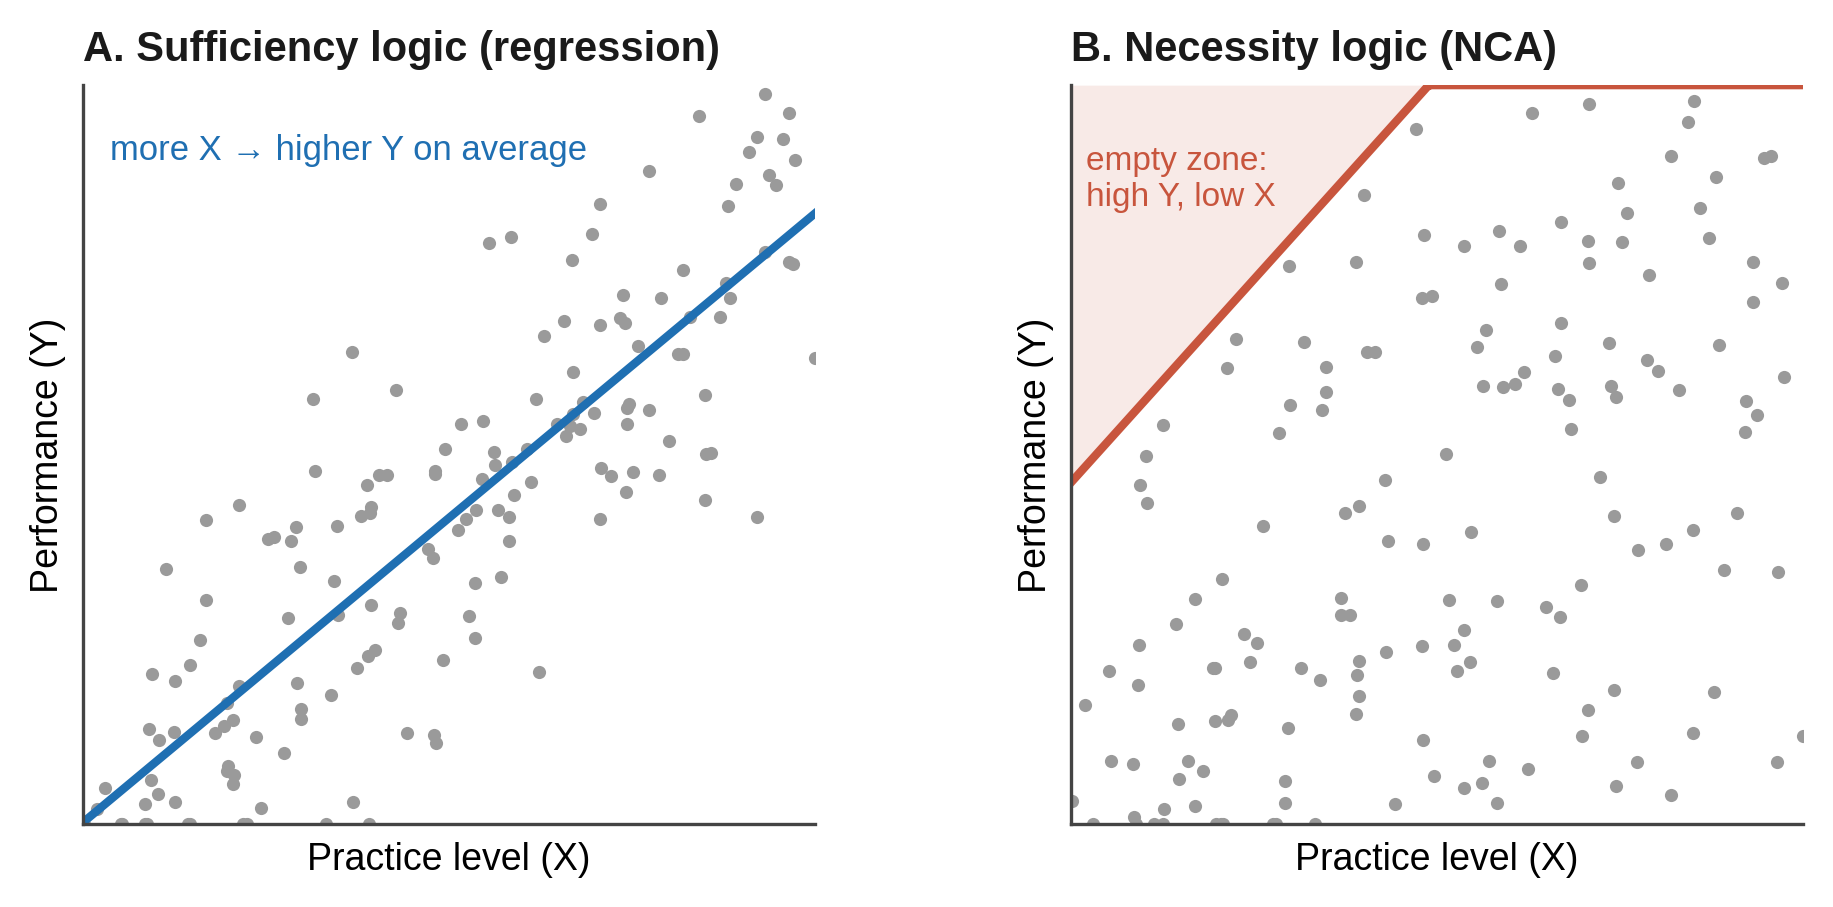

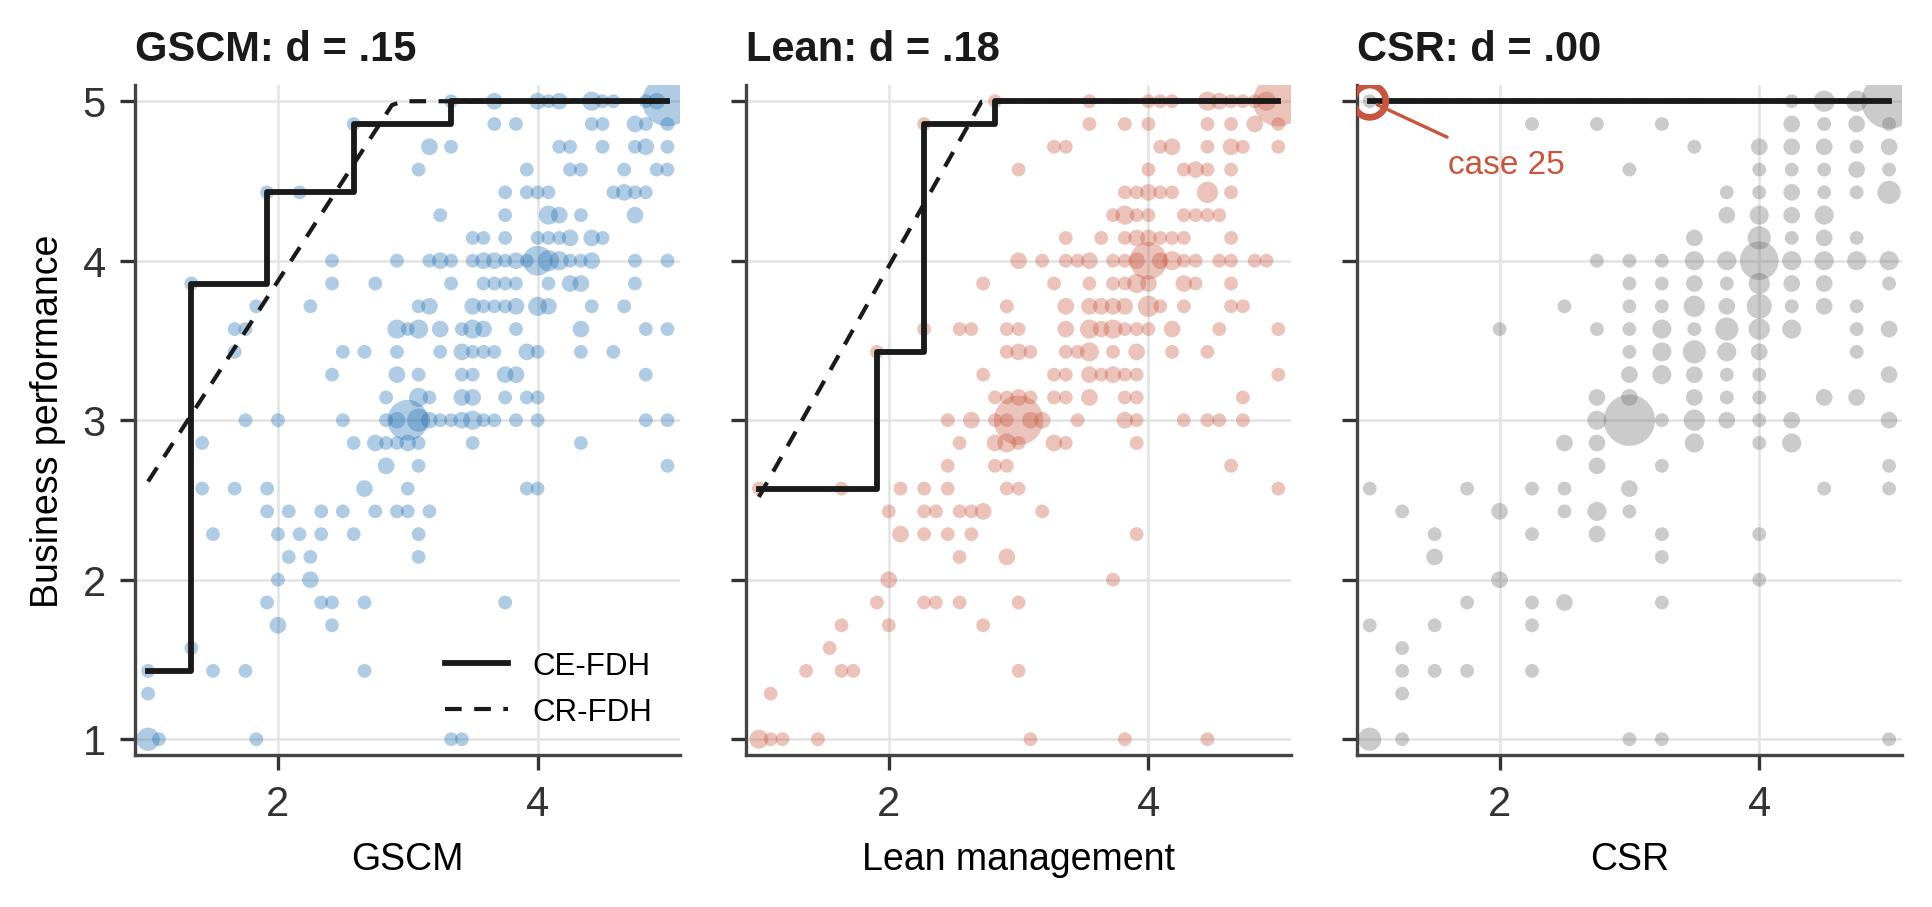

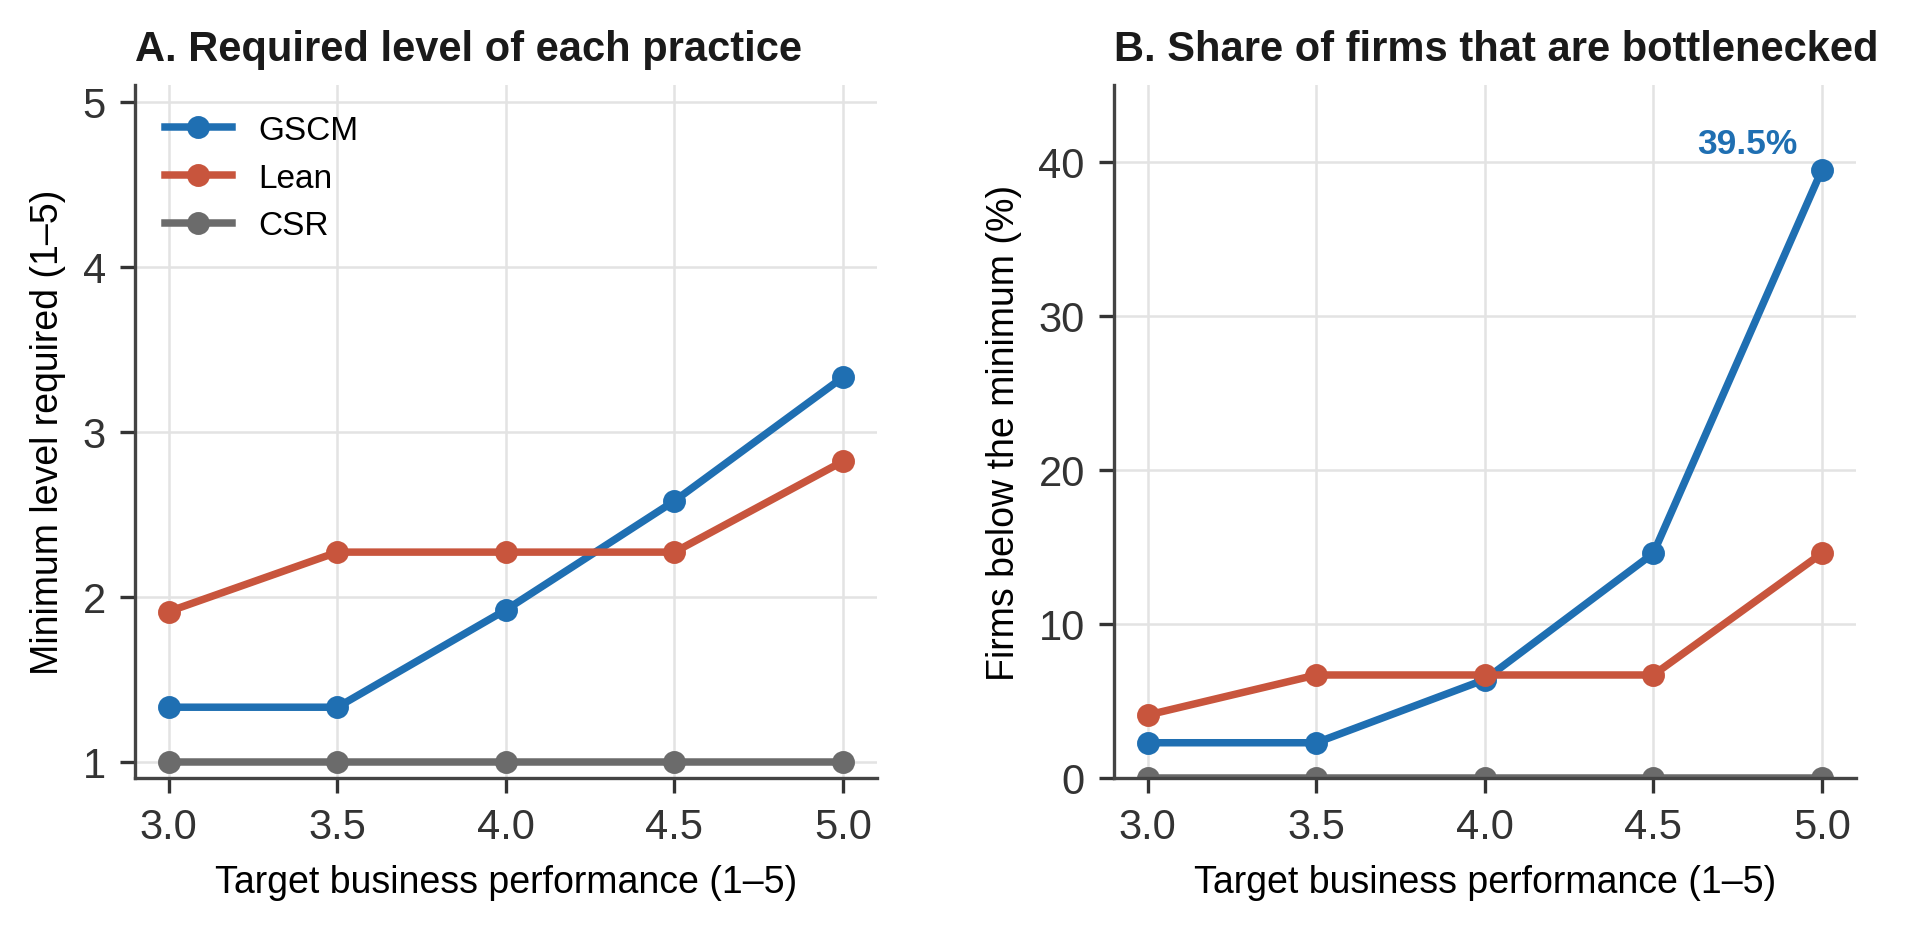

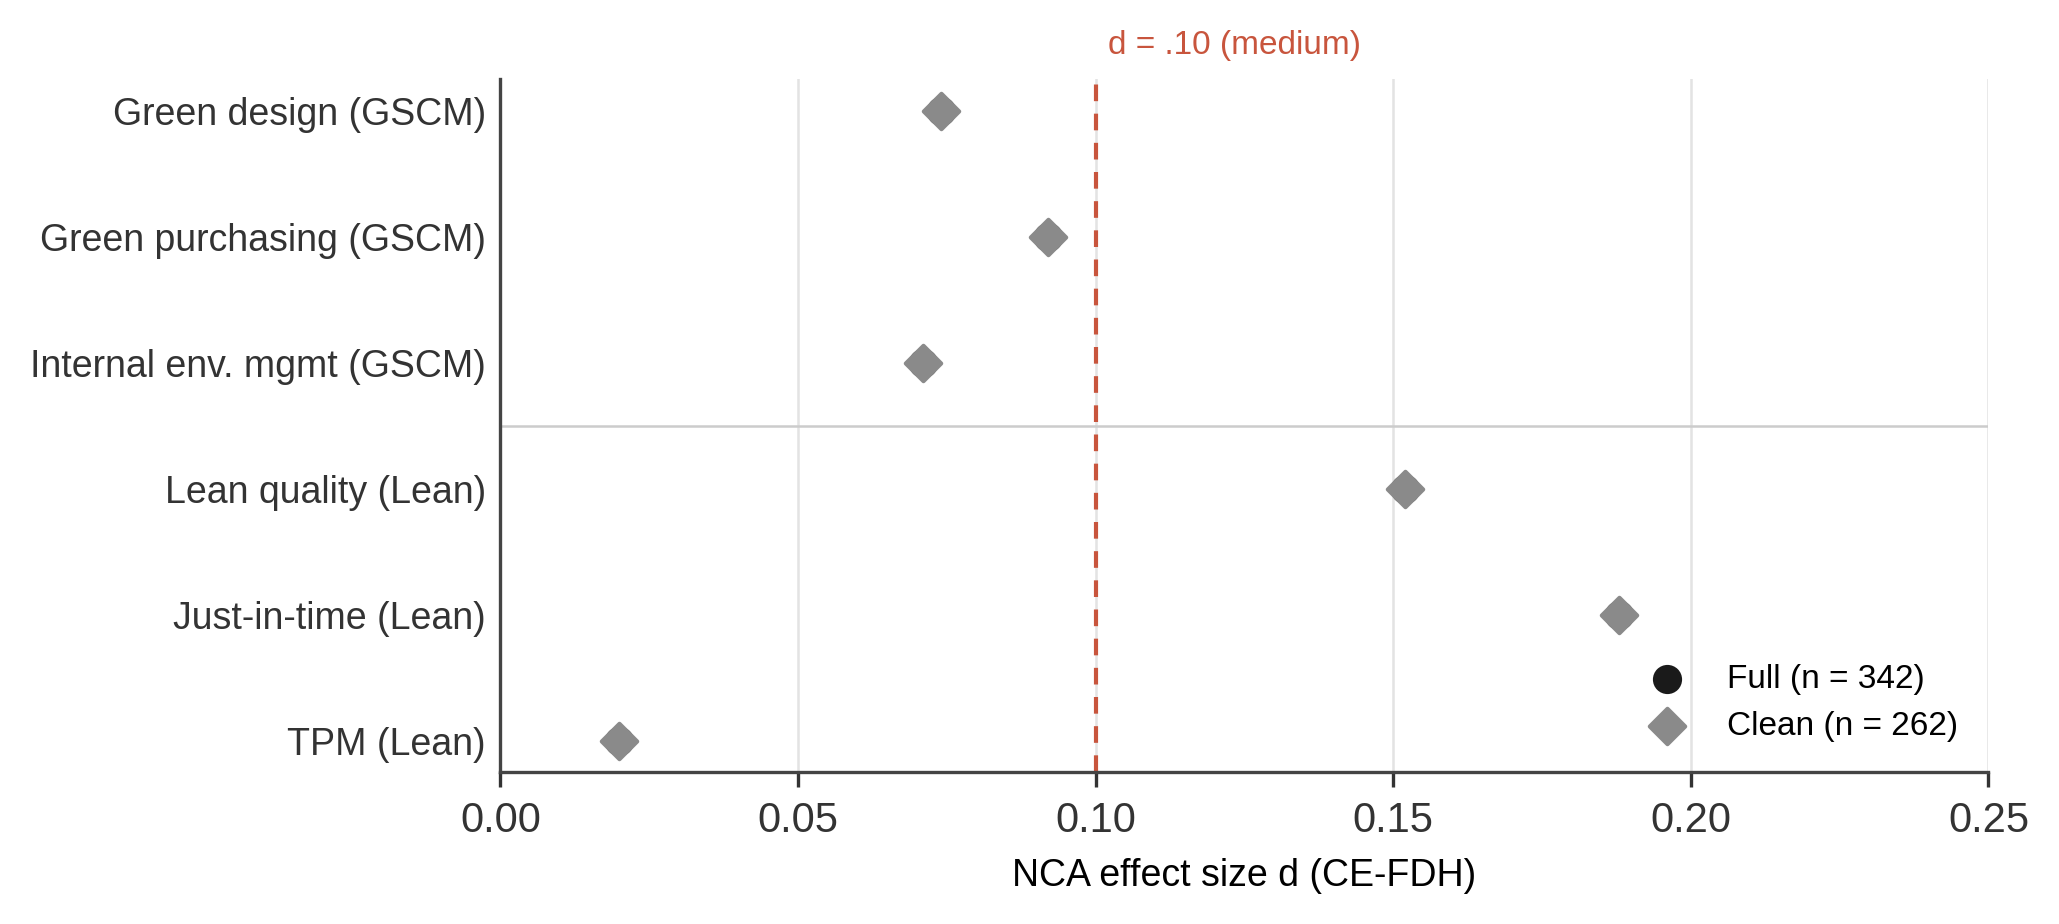

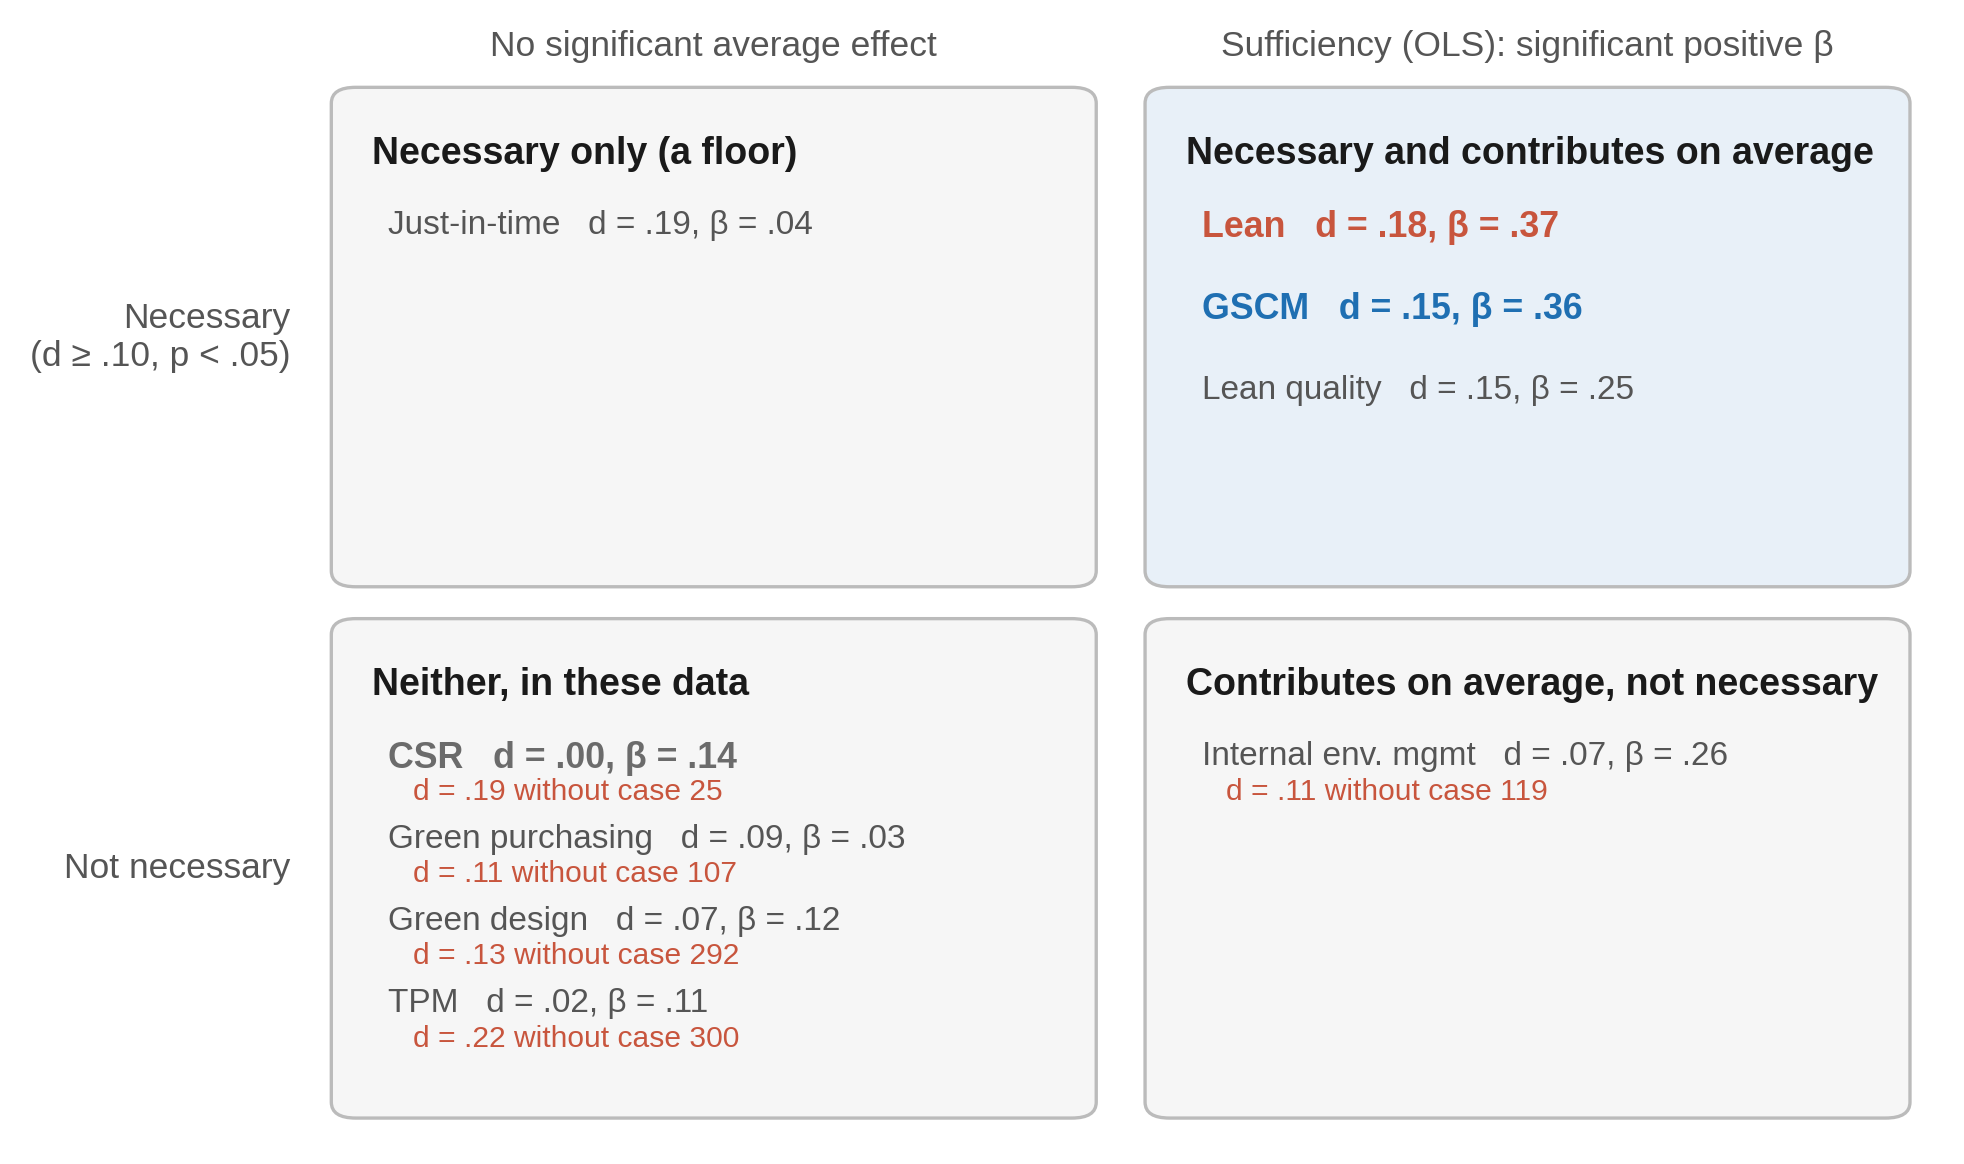

Figures 1-4 and S1 saved


In [14]:
# ---- nca_figures.py: Figures 1-3 and S1 ----
import warnings; warnings.filterwarnings("ignore")
import os, numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib import font_manager
try:
    from IPython.display import Image, display
except ImportError:
    display = None
_fams = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Liberation Sans", "Arial", "DejaVu Sans"] if f in _fams), "DejaVu Sans")
plt.rcParams.update({"font.family": FONT, "font.size": 10, "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.linewidth": 0.8, "xtick.color": "#333333", "ytick.color": "#333333"})
INK, MUTED, EDGE, GRID = "#1a1a1a", "#555555", "#333333", "#e3e3e3"
COL = {"GSCM": "#1f6fb2", "LEAN": "#c8553d", "CSR": "#6b6b6b"}
NAME = {"GSCM": "Green supply chain management", "LEAN": "Lean management", "CSR": "Corporate social responsibility"}
O, F = "output/", "figures/"; os.makedirs(F, exist_ok=True)
def save(fig, name):
    for ext in ("png", "pdf", "tiff"):
        kw = {"dpi": 600, "pil_kwargs": {"compression": "tiff_lzw"}} if ext == "tiff" else {"dpi": 300}
        fig.savefig(F + name + "." + ext, bbox_inches="tight", facecolor="white", **kw)
    plt.close(fig)
    if display: display(Image(F + name + ".png", width=760))
def fmt(x, d=2):
    s = f"{x:.{d}f}"; s = s.replace("0.", ".", 1) if abs(x) < 1 else s; return s.replace("-", "−")
sc = pd.read_csv(O + "N_X3_scores_full.csv"); t3 = pd.read_csv(O + "N_T3_effect_sizes.csv"); OUT = int(pd.read_csv(O + "settings.csv").OUT_CASE.iloc[0])
T = lambda c: t3[(t3.Sample == "Full (n = 342)") & (t3.Condition == c)].iloc[0]

# ---------- Figure 1: sufficiency vs necessity logic ----------
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.2), gridspec_kw={"wspace": 0.35})
rng = np.random.default_rng(3); xs = rng.uniform(1, 5, 160)
ys1 = np.clip(1 + 0.8 * (xs - 1) + rng.normal(0, .6, 160), 1, 5)
ys2 = np.clip(rng.uniform(1, 5, 160) * np.minimum(1, 0.35 + 0.22 * xs), 1, 5)
for ax, ys, ttl in [(axs[0], ys1, "A. Sufficiency logic (regression)"), (axs[1], ys2, "B. Necessity logic (NCA)")]:
    ax.scatter(xs, ys, s=10, color="#9a9a9a", lw=0); ax.set_xlim(1, 5); ax.set_ylim(1, 5)
    ax.set_xlabel("Practice level (X)", fontsize=9); ax.set_ylabel("Performance (Y)", fontsize=9); ax.set_title(ttl, fontsize=10, fontweight="bold", loc="left", color=INK)
    ax.set_xticks([]); ax.set_yticks([])
b = np.polyfit(xs, ys1, 1); xx = np.linspace(1, 5, 50); axs[0].plot(xx, np.polyval(b, xx), color=COL["GSCM"], lw=2)
axs[0].text(1.15, 4.6, "more X → higher Y on average", fontsize=8.3, color=COL["GSCM"])
cx = np.linspace(1, 5, 200); cy = np.clip(5 * np.minimum(1, 0.35 + 0.22 * cx), 1, 5)
axs[1].plot(cx, cy, color=COL["LEAN"], lw=2); axs[1].fill_between(cx, cy, 5, color=COL["LEAN"], alpha=0.12, lw=0)
axs[1].text(1.08, 4.35, "empty zone:\nhigh Y, low X", fontsize=8, color=COL["LEAN"])
save(fig, "Figure1_necessity_logic")

# ---------- Figure 2: scatter plots with ceiling lines ----------
def ce_step(x, y):
    o = np.argsort(x, kind="mergesort"); xs_, ys_ = x[o], y[o]; cm = np.maximum.accumulate(ys_)
    ux = np.unique(xs_); idx = np.searchsorted(xs_, ux, side="right") - 1; return ux, cm[idx]
def cr(x, y):
    ux, c = ce_step(x, y); k = np.r_[True, np.diff(c) > 0]; b, a = np.polyfit(ux[k], c[k], 1); return a, b
fig, axs = plt.subplots(1, 3, figsize=(7.6, 2.9), sharey=True, gridspec_kw={"wspace": 0.12})
for ax, X in zip(axs, ["GSCM", "LEAN", "CSR"]):
    x, y = sc[X].values, sc.PERF.values
    pts = pd.DataFrame({"x": x, "y": y}).value_counts().reset_index(name="k")
    ax.scatter(pts.x, pts.y, s=6 + 5 * pts.k, color=COL[X], alpha=0.35, lw=0)
    ux, c = ce_step(x, y); ax.step(np.r_[ux, x.max()], np.r_[c, c[-1]], where="post", color=INK, lw=1.4, label="CE-FDH")
    a, b = cr(x, y); xx = np.linspace(x.min(), x.max(), 50); ax.plot(xx, np.clip(a + b * xx, y.min(), y.max()), color=INK, lw=1.0, ls=(0, (4, 3)), label="CR-FDH")
    o = sc[sc.case == OUT]
    if X == "CSR": ax.scatter(o[X], o.PERF, s=60, facecolor="none", edgecolor=COL["LEAN"], lw=1.6, zorder=4); ax.annotate(f"case {OUT}", (o[X].iloc[0], o.PERF.iloc[0]), xytext=(1.6, 4.55), fontsize=8, color=COL["LEAN"], arrowprops=dict(arrowstyle="-", color=COL["LEAN"], lw=0.8))
    r = T(X); ax.set_title(f"{X if X != 'LEAN' else 'Lean'}: d = {fmt(r.d_CE, 2)}", fontsize=10, fontweight="bold", loc="left", color=INK)
    ax.set_xlim(0.9, 5.1); ax.set_ylim(0.9, 5.1); ax.set_xlabel(NAME[X].replace("Green supply chain management", "GSCM").replace("Corporate social responsibility", "CSR"), fontsize=9)
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
axs[0].set_ylabel("Business performance", fontsize=9); axs[0].legend(fontsize=7.5, frameon=False, loc="lower right")
save(fig, "Figure2_ceiling_plots")

# ---------- Figure 3: bottlenecks ----------
t4 = pd.read_csv(O + "N_T4_bottleneck.csv")
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), gridspec_kw={"wspace": 0.32})
for X in ["GSCM", "LEAN", "CSR"]:
    axs[0].plot(t4.PERF_level, t4[f"{X}_required"], marker="o", ms=4.5, lw=1.8, color=COL[X], label={"GSCM": "GSCM", "LEAN": "Lean", "CSR": "CSR"}[X])
    axs[1].plot(t4.PERF_level, t4[f"{X}_share_below"], marker="o", ms=4.5, lw=1.8, color=COL[X])
axs[0].set_ylim(0.9, 5.1); axs[0].set_ylabel("Minimum level required (1–5)", fontsize=9); axs[0].legend(fontsize=8, frameon=False, loc="upper left")
axs[1].set_ylabel("Firms below the minimum (%)", fontsize=9); axs[1].set_ylim(0, max(45, t4[[c for c in t4 if c.endswith("share_below")]].values.max() + 5))
for ax, ttl in zip(axs, ["A. Required level of each practice", "B. Share of firms that are bottlenecked"]):
    ax.set_xlabel("Target business performance (1–5)", fontsize=9); ax.set_xticks(t4.PERF_level); ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_title(ttl, fontsize=10, fontweight="bold", loc="left", color=INK)
r5 = t4[t4.PERF_level == 5.0].iloc[0]
axs[1].annotate(f"{fmt(r5.GSCM_share_below, 1)}%", (5.0, r5.GSCM_share_below), xytext=(-30, 4), textcoords="offset points", fontsize=8.5, color=COL["GSCM"], fontweight="bold")
save(fig, "Figure3_bottlenecks")

# ---------- Figure S1: dimension-level effect sizes ----------
dims = ["GD", "GP", "IEM", "LQ", "JIT", "TPM"]; lab = {"GD": "Green design", "GP": "Green purchasing", "IEM": "Internal env. mgmt", "LQ": "Lean quality", "JIT": "Just-in-time", "TPM": "TPM"}
fig, ax = plt.subplots(figsize=(6.4, 3.0)); y = np.arange(len(dims))[::-1]
for s, m, col in [("Full (n = 342)", "o", INK), ("Clean (n = 262)", "D", "#8a8a8a")]:
    v = t3[t3.Sample == s].set_index("Condition").loc[dims, "d_CE"]; ax.scatter(v, y, marker=m, s=36, color=col, label=s, zorder=3)
ax.axvline(0.10, color=COL["LEAN"], lw=1, ls=(0, (4, 3))); ax.text(0.102, y[0] + 0.45, "d = .10 (medium)", fontsize=8, color=COL["LEAN"])
ax.set_yticks(y); ax.set_yticklabels([f"{lab[k]} ({'GSCM' if k in ['GD', 'GP', 'IEM'] else 'Lean'})" for k in dims], fontsize=9); ax.tick_params(axis="y", length=0)
ax.set_xlabel("NCA effect size d (CE-FDH)", fontsize=9); ax.set_xlim(0, 0.25); ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.axhline(2.5, color="#cccccc", lw=0.6); ax.legend(fontsize=8, frameon=False, loc="lower right")
save(fig, "FigureS1_dimensions")

# ---------- Figure 4: necessity x sufficiency map ----------
mp = pd.read_csv(O + "N_X6_map.csv"); t5b = pd.read_csv(O + "N_T5b_ceiling_diagnostics.csv").set_index("Condition")
SH = {"GSCM": "GSCM", "LEAN": "Lean", "CSR": "CSR", "GD": "Green design", "GP": "Green purchasing", "IEM": "Internal env. mgmt", "LQ": "Lean quality", "JIT": "Just-in-time", "TPM": "TPM"}
fig, ax = plt.subplots(figsize=(7.0, 4.6)); ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.axis("off")
cells = {(True, True): (1, 1, "Necessary and contributes on average"), (True, False): (0, 1, "Necessary only (a floor)"),
         (False, True): (1, 0, "Contributes on average, not necessary"), (False, False): (0, 0, "Neither, in these data")}
for (nec, suf), (cx, cy, ttl) in cells.items():
    fc = "#e8f0f8" if nec and suf else "#f6f6f6"
    ax.add_patch(FancyBboxPatch((cx + .03, cy + .03), .94, .94, boxstyle="round,pad=0,rounding_size=0.03", fc=fc, ec="#bbbbbb", lw=0.8))
    ax.text(cx + .08, cy + .88, ttl, fontsize=9, fontweight="bold", color=INK, va="top")
    sub = mp[(mp.necessary == nec) & (mp.sufficient == suf)].sort_values(["level", "d_CE"], ascending=[True, False])
    for j, (_, r) in enumerate(sub.iterrows()):
        bund = r.level == "bundle"; col = COL.get(r.Condition, MUTED)
        lab = f"{SH[r.Condition]}   d = {fmt(r.d_CE)}, β = {fmt(r.beta)}"
        ax.text(cx + .1, cy + .74 - j * .155, lab, fontsize=8.6 if bund else 8.0, color=col if bund else MUTED, fontweight="bold" if bund else "normal", va="top")
        if r.Condition in t5b.index and bool(t5b.loc[r.Condition, "size_changes"]):
            rr = t5b.loc[r.Condition]
            ax.text(cx + .13, cy + .74 - j * .155 - .068, f"d = {fmt(rr.d_CE + rr.max_change)} without case {int(rr.max_case)}", fontsize=7.2, color=COL["LEAN"], va="top")
ax.text(1.5, 2.03, "Sufficiency (OLS): significant positive β", ha="center", fontsize=8.5, color=MUTED)
ax.text(0.5, 2.03, "No significant average effect", ha="center", fontsize=8.5, color=MUTED)
ax.text(-0.02, 1.5, "Necessary\n(d ≥ .10, p < .05)", ha="right", va="center", fontsize=8.5, color=MUTED)
ax.text(-0.02, 0.5, "Not necessary", ha="right", va="center", fontsize=8.5, color=MUTED)
save(fig, "Figure4_necessity_sufficiency_map")
print("Figures 1-4 and S1 saved")

## Step 8 — Word file: Tables 1–6, Figures 1–4 and S1 (APA 7)

In [15]:
import pandas as pd, numpy as np
from docx import Document
from docx.shared import Pt, Cm, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH, WD_BREAK
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT
from docx.oxml.ns import qn
from docx.oxml import OxmlElement

O, F = "output/", "figures/"
FONT = "Times New Roman"
rd = lambda f: pd.read_csv(O + f)

# ---------- number formatting (APA 7) ----------
def apa(x, d=2):
    try: v = float(x)
    except (TypeError, ValueError): return "—"
    if np.isnan(v): return "—"
    s = f"{v:.{d}f}"
    if abs(v) < 1: s = s.replace("0.", ".", 1)
    return s.replace("-", "−")
def fx(x, d=2): return f"{float(x):.{d}f}".replace("-", "−")
def pval(x): v = float(x); return "< .001" if v < .001 else apa(v, 3)
def star(p): v = float(p); return "***" if v < .001 else "**" if v < .01 else "*" if v < .05 else ""
def ci(lo, hi): return f"[{apa(lo)}, {apa(hi)}]"

# ---------- document + APA table helpers ----------
doc = Document()
sec = doc.sections[0]
sec.page_width, sec.page_height = Cm(21.0), Cm(29.7)
for m in ("left_margin", "right_margin", "top_margin", "bottom_margin"): setattr(sec, m, Cm(2.0))
st = doc.styles["Normal"]; st.font.name = FONT; st.font.size = Pt(11)
st.element.rPr.rFonts.set(qn("w:eastAsia"), FONT)
TEXT_W = 17.0  # cm

def para(text="", size=11, bold=False, italic=False, align=None, before=0, after=6, keep=False):
    p = doc.add_paragraph(); pf = p.paragraph_format
    pf.space_before, pf.space_after, pf.keep_with_next = Pt(before), Pt(after), keep
    if align: p.alignment = align
    if text:
        r = p.add_run(text); r.font.size, r.bold, r.italic, r.font.name = Pt(size), bold, italic, FONT
    return p

def page_break(): doc.add_paragraph().add_run().add_break(WD_BREAK.PAGE)

def table_title(n, title):
    para(f"Table {n}", bold=True, before=12, after=0, keep=True)
    para(title, italic=True, after=6, keep=True)

def note(text, stars=False):
    p = para(size=9, before=4, after=12)
    r = p.add_run("Note. "); r.italic, r.font.size = True, Pt(9)
    r = p.add_run(text + (" * p < .05. ** p < .01. *** p < .001." if stars else "")); r.font.size = Pt(9)

def _borders(cell, top=False, bottom=False):
    tcPr = cell._tc.get_or_add_tcPr()
    for old in tcPr.findall(qn("w:tcBorders")): tcPr.remove(old)
    b = OxmlElement("w:tcBorders")
    for edge in ("top", "left", "bottom", "right"):
        el = OxmlElement(f"w:{edge}"); on = (edge == "top" and top) or (edge == "bottom" and bottom)
        el.set(qn("w:val"), "single" if on else "nil")
        if on: el.set(qn("w:sz"), "6"); el.set(qn("w:color"), "000000"); el.set(qn("w:space"), "0")
        b.append(el)
    tcPr.append(b)

def _write(cell, text, bold=False, italic=False, align="left", indent=0, size=10):
    cell.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
    p = cell.paragraphs[0]; p.text = ""
    p.alignment = {"left": WD_ALIGN_PARAGRAPH.LEFT, "center": WD_ALIGN_PARAGRAPH.CENTER}[align]
    pf = p.paragraph_format; pf.space_before = pf.space_after = Pt(1.5)
    if indent: pf.left_indent = Cm(indent)
    r = p.add_run(str(text)); r.bold, r.italic, r.font.size, r.font.name = bold, italic, Pt(size), FONT

def apa_table(widths_cm, header_rows, body):
    """header_rows: list of rows; each row a list of dicts {t, span=1, italic=False, rule=False}.
       body: list of dicts {cells, bold, italic, indent, span (first cell spans n columns), left (extra left-aligned cols)}"""
    ncol = len(widths_cm)
    t = doc.add_table(rows=len(header_rows) + len(body), cols=ncol)
    t.alignment = WD_TABLE_ALIGNMENT.CENTER; t.autofit = False
    tblPr = t._tbl.tblPr
    lay = OxmlElement("w:tblLayout"); lay.set(qn("w:type"), "fixed"); tblPr.append(lay)
    tw = tblPr.find(qn("w:tblW"))
    if tw is None: tw = OxmlElement("w:tblW"); tblPr.append(tw)
    tw.set(qn("w:w"), str(int(sum(widths_cm) * 567))); tw.set(qn("w:type"), "dxa")
    for gc, w in zip(t._tbl.tblGrid.findall(qn("w:gridCol")), widths_cm): gc.set(qn("w:w"), str(int(w * 567)))
    for row in t.rows:
        for j, c in enumerate(row.cells): c.width = Cm(widths_cm[j]); _borders(c)
    nh = len(header_rows)
    for ri, hr in enumerate(header_rows):
        col = 0
        for h in hr:
            span = h.get("span", 1); c = t.cell(ri, col)
            if span > 1: c = c.merge(t.cell(ri, col + span - 1))
            _write(c, h["t"], italic=h.get("italic", False), align="left" if (col == 0 and span == 1) else "center")
            _borders(c, top=(ri == 0), bottom=(ri == nh - 1) or h.get("rule", False))
            col += span
    for bi, r in enumerate(body):
        ri = nh + bi; last = bi == len(body) - 1; cells = r["cells"]; span = r.get("span", 1)
        c0 = t.cell(ri, 0)
        if span > 1: c0 = c0.merge(t.cell(ri, span - 1))
        _write(c0, cells[0], bold=r.get("bold", False), italic=r.get("italic", False), indent=r.get("indent", 0))
        _borders(c0, bottom=last)
        for k, v in enumerate(cells[1:]):
            j = span + k; c = t.cell(ri, j)
            _write(c, v, bold=r.get("bold", False), align="left" if j in r.get("left", []) else "center")
            _borders(c, bottom=last)
        for j in range(span + len(cells) - 1, ncol): _borders(t.cell(ri, j), bottom=last)
    for row in t.rows:  # keep rows from splitting across pages
        trPr = row._tr.get_or_add_trPr(); cs = OxmlElement("w:cantSplit"); trPr.append(cs)
    return t

def figure(n, title, file, width_in, note_text):
    para(f"Figure {n}", bold=True, before=12, after=0, keep=True)
    para(title, italic=True, after=6, keep=True)
    p = para(align=WD_ALIGN_PARAGRAPH.CENTER, keep=True); p.add_run().add_picture(F + file, width=Inches(width_in))
    note(note_text)


# ---------- data ----------
prof, meas = rd("N_T1_profile.csv"), rd("C_T2_measurement.csv")
t3, t4, t5, t6, ol, desc = rd("N_T3_effect_sizes.csv"), rd("N_T4_bottleneck.csv"), rd("N_T5_robustness.csv"), rd("N_T6_sufficiency_necessity.csv"), rd("N_X1_outliers.csv"), pd.read_csv(O + "N_X2_descriptives.csv", index_col=0)
t5b, t6i, flow, mp = rd("N_T5b_ceiling_diagnostics.csv"), rd("N_X5_interaction.csv"), rd("N_T0_sample_flow.csv"), rd("N_X6_map.csv")
st = rd("settings.csv").iloc[0]; BP, OUT = int(st.B_PERM), int(st.OUT_CASE)
NM = {"GSCM": "Green supply chain management", "LEAN": "Lean management", "CSR": "Corporate social responsibility",
      "GD": "Green design", "GP": "Green purchasing", "IEM": "Internal environmental management", "LQ": "Lean quality management", "JIT": "Just-in-time", "TPM": "Total productive maintenance"}
DIMS_ = ["GD", "GP", "IEM", "LQ", "JIT", "TPM"]
def pn(x): v = float(x); return "< .001" if v < .001 else apa(v, 3)

para("Results: tables and figures", size=16, bold=True, after=6)
para("Necessary but Not Sufficient? Green Supply Chain Management, Lean and CSR as Necessary Conditions for Business Performance in Saudi Industry "
     "(SEDBM 2026, Topic 09, N019).")
para(f"All values computed from the public dataset (Alkandi, 2024; Mendeley Data, doi:10.17632/nmfffwb5wv.1, CC BY 4.0). Necessary Condition Analysis "
     f"(Dul, 2016) with ceiling envelopment (CE-FDH) and ceiling regression (CR-FDH); permutation tests with {BP:,} replications. Tables follow APA 7th edition.")
page_break()

# ---------- Table 1 ----------
table_title(1, "Sample Flow and Profile of Respondents")
body = [{"cells": ["Panel A. Sample flow"], "span": 4, "italic": True}]
for _, r in flow.iterrows():
    ind = 0.35 if r.Step.startswith("Flagged") else 0
    body.append({"cells": [r.Step, "", str(int(r.n)), ""], "span": 2, "indent": ind, "bold": r.Step.startswith("Analysis sample")})
body.append({"cells": ["Panel B. Profile of the analysis sample (n = 342)"], "span": 4, "italic": True})
LBL = {"industry": "Industry", "size": "Firm size (employees)", "position": "Managerial position", "gender": "Gender", "edu": "Education"}
last = None
for _, r in prof.iterrows():
    body.append({"cells": [LBL[r.Characteristic] if r.Characteristic != last else "", str(r.Category).replace("Lower Manger", "Lower manager"), int(r.n), fx(r.pct, 1)], "left": [1]})
    last = r.Characteristic
apa_table([4.2, 8.4, 2.0, 2.0], [[{"t": "Characteristic"}, {"t": "Category"}, {"t": "n", "italic": True}, {"t": "%"}]], body)
note("Managers in industrial-sector organisations in the Eastern Province of Saudi Arabia (Alkandi, 2024). Panel A: the screening rules were set before the analysis; "
     "a response can meet more than one rule (all 45 respondents with identical answers to all items also meet the consecutive-answer rule). Flagged responses stay in the "
     "analysis sample and are removed only in the clean-sample robustness check (Table 5), because NCA results depend on the cases that define the ceiling, not on the "
     "bulk of the data. The public file has no missing item values. Its time stamps all fall between 10:00 and 10:59 on 27 February 2024, so completion time cannot be "
     "used for screening. Category labels in Panel B are reproduced from the questionnaire.")
page_break()

# ---------- Table 2 ----------
table_title(2, "Measurement Quality and Descriptive Statistics of the Composite Scores")
mf, mc = meas[meas.Sample == "Consented 342"].set_index("Construct"), meas[meas.Sample == "Clean 262"].set_index("Construct")
dims_ = [("GD", "GSCM"), ("GP", "GSCM"), ("IEM", "GSCM"), ("LQ", "LEAN"), ("JIT", "LEAN"), ("TPM", "LEAN"), ("CSR", "CSR"), ("MP", "PERF"), ("FP", "PERF")]
CN = dict(NM, MP="Market performance", FP="Financial performance")
body = []
for grp, lab in [("GSCM", "Green supply chain management (12 items)"), ("LEAN", "Lean management (11 items)"), ("CSR", "Corporate social responsibility (4 items)"), ("PERF", "Business performance (7 items)")]:
    dg = desc.loc[grp]; body.append({"cells": [lab, "", "", "", "", fx(dg["mean"]), fx(dg["std"])], "bold": True})
    for k, g in dims_:
        if g != grp or k == "CSR": continue
        body.append({"cells": [CN[k], f"{apa(mf.loc[k, 'Loading_min'])}–{apa(mf.loc[k, 'Loading_max'])}", apa(mf.loc[k, "Alpha"]), apa(mf.loc[k, "CR"]), apa(mf.loc[k, "AVE"]), "", ""], "indent": 0.35})
    if grp == "CSR":
        body[-1]["cells"][1:5] = [f"{apa(mf.loc['CSR', 'Loading_min'])}–{apa(mf.loc['CSR', 'Loading_max'])}", apa(mf.loc["CSR", "Alpha"]), apa(mf.loc["CSR", "CR"]), apa(mf.loc["CSR", "AVE"])]
apa_table([7.4, 2.0, 1.4, 1.4, 1.4, 1.5, 1.5], [[{"t": "Construct / dimension"}, {"t": "λ range"}, {"t": "α"}, {"t": "CR"}, {"t": "AVE"}, {"t": "M", "italic": True}, {"t": "SD", "italic": True}]], body)
f0 = mf.iloc[0]
note(f"n = 342. Loadings, composite reliability (CR) and average variance extracted (AVE) from a nine-factor confirmatory factor analysis (MLR): "
     f"χ²({int(f0.df)}) = {fx(f0.chisq, 1)}, CFI = {apa(f0.cfi, 3)}, RMSEA = {apa(f0.rmsea, 3)}, SRMR = {apa(f0.srmr, 3)}. NCA uses the mean of the items of each construct "
     "(range 1–5); means and standard deviations refer to these composite scores. Business performance combines the market and financial performance items, as in the original study.")
page_break()

# ---------- Table 3 ----------
table_title(3, "Necessary Condition Analysis: Effect Sizes and Significance (RQ1)")
R3 = lambda s, c: t3[(t3.Sample == s) & (t3.Condition == c)].iloc[0]
body = [{"cells": ["Panel A. Practice bundles"], "span": 9, "italic": True}]
for c in ["GSCM", "LEAN", "CSR", "Panel B. Practice dimensions", "GD", "GP", "IEM", "LQ", "JIT", "TPM"]:
    if c.startswith("Panel"): body.append({"cells": [c], "span": 9, "italic": True}); continue
    f, k = R3("Full (n = 342)", c), R3("Clean (n = 262)", c)
    verdict = "Necessary (medium)" if f.necessary else ("Inconclusive (one case)" if c in ("CSR", "TPM") else "Not necessary")
    body.append({"cells": [NM[c], apa(f.d_CE), pn(f.p_CE), apa(f.d_CR), pn(f.p_CR), fx(f.accuracy_CR, 1), apa(k.d_CE), pn(k.p_CE), verdict], "left": [8],
                 "indent": 0.35 if c in DIMS_ else 0})
apa_table([4.6, 1.2, 1.3, 1.2, 1.3, 1.3, 1.2, 1.3, 3.1], [
    [{"t": ""}, {"t": "Full sample (n = 342)", "span": 5, "rule": True}, {"t": "Clean (n = 262)", "span": 2, "rule": True}, {"t": ""}],
    [{"t": "Condition"}, {"t": "d CE"}, {"t": "p", "italic": True}, {"t": "d CR"}, {"t": "p", "italic": True}, {"t": "Acc. %"}, {"t": "d CE"}, {"t": "p", "italic": True}, {"t": "Conclusion"}]], body)
note(f"Outcome: business performance (composite, 1–5). d = NCA effect size, the size of the empty ceiling zone relative to the scope (Dul, 2016): 0–.10 small, "
     f".10–.30 medium, .30–.50 large, > .50 very large. CE = ceiling envelopment with free disposal hull, the main ceiling because the scores are discrete; CR = ceiling "
     f"regression through the CE-FDH peers. Acc. = ceiling accuracy, the share of cases on or below the CR-FDH line (CE-FDH is 100% by definition). p values from "
     f"approximate permutation tests ({BP:,} replications; Dul et al., 2020). A condition is treated as necessary when d ≥ .10 and p < .05. Panel B tests each dimension "
     f"on its own, so the necessity logic does not rest on averaged scores. Inconclusive: d depends on a single case (Table 5, Panel B). The clean-sample values equal the "
     f"full-sample values because no ceiling-defining case was flagged by the screening rules.")

# ---------- Table 4 ----------
table_title(4, "Bottleneck Table: Minimum Level of Each Practice Required for a Given Level of Business Performance (RQ2)")
para("Panel A. Minimum levels (CE-FDH, full sample)", italic=True, after=4, keep=True)
body = [{"cells": [fx(r.PERF_level, 1), f"{fx(r.share_reaching, 1)}%", fx(r.GSCM_required), f"{fx(r.GSCM_share_below, 1)}%", fx(r.LEAN_required), f"{fx(r.LEAN_share_below, 1)}%",
                   fx(r.CSR_required), f"{fx(r.CSR_share_below, 1)}%"]} for _, r in t4.iterrows()]
apa_table([2.6, 2.2, 1.8, 2.0, 1.8, 2.0, 1.8, 2.0], [
    [{"t": "Target performance"}, {"t": "Firms reaching it"}, {"t": "GSCM", "span": 2, "rule": True}, {"t": "Lean management", "span": 2, "rule": True}, {"t": "CSR", "span": 2, "rule": True}],
    [{"t": "(1–5)"}, {"t": ""}, {"t": "Minimum"}, {"t": "Below"}, {"t": "Minimum"}, {"t": "Below"}, {"t": "Minimum"}, {"t": "Below"}]], body)
r5 = t4[t4.PERF_level == 5.0].iloc[0]
note(f"Panel A. n = 342. CE-FDH ceiling, values on the original 1–5 scale. Minimum = the lowest level of the practice observed among firms that reach the target "
     f"performance; Below = share of all firms whose practice level is under that minimum. These are benchmarks for this sample, not universal thresholds: "
     f"no firm in the sample reached the top score with GSCM below {fx(r5.GSCM_required)}. Without case {OUT}, the minimum CSR level for top performance rises from "
     f"{fx(r5.CSR_required)} to {fx(r5.CSR_required_noOut)} and the minimum lean level from {fx(r5.LEAN_required)} to {fx(r5.LEAN_required_noOut)}.")

para("Panel B. Sensitivity of the minimums to the ceiling line and the sample", italic=True, before=6, after=4, keep=True)
body = []
for _, r in t4[t4.PERF_level >= 4.0].iterrows():
    body.append({"cells": [fx(r.PERF_level, 1), f"{int(r.n_reaching)} / {int(r.n_reaching_clean)}", fx(r.GSCM_required), fx(r.GSCM_required_CR), fx(r.GSCM_required_clean),
                           fx(r.LEAN_required), fx(r.LEAN_required_CR), fx(r.LEAN_required_clean)]})
apa_table([2.6, 2.8, 1.9, 1.9, 1.9, 1.9, 1.9, 1.9], [
    [{"t": "Target"}, {"t": "Firms reaching"}, {"t": "GSCM minimum", "span": 3, "rule": True}, {"t": "Lean minimum", "span": 3, "rule": True}],
    [{"t": "(1–5)"}, {"t": "full / clean"}, {"t": "CE"}, {"t": "CR"}, {"t": "Clean"}, {"t": "CE"}, {"t": "CR"}, {"t": "Clean"}]], body)
note("Panel B. CE = CE-FDH ceiling (main); CR = CR-FDH ceiling; Clean = CE-FDH in the clean sample (n = 262). Following Dul, Hauff and Bouncken (2023), bottlenecks are "
     "reported for several targets because the top score is reached by few firms. The CR-FDH line gives lower minimums at the top because it smooths the step ceiling. "
     "The CE minimums are the same in both samples at every target.")
page_break()

# ---------- Table 5 ----------
table_title(5, "Robustness of the NCA Effect Sizes")
para("Panel A. Alternative ceilings and samples", italic=True, after=4, keep=True)
body = [{"cells": [r.Specification, int(r.n)] + sum([[apa(r[f"{c}_d"]), pn(r[f"{c}_p"])] for c in ["GSCM", "LEAN", "CSR"]], [])} for _, r in t5.iterrows()]
apa_table([6.2, 1.1, 1.4, 1.5, 1.4, 1.5, 1.4, 1.5], [
    [{"t": ""}, {"t": ""}, {"t": "GSCM", "span": 2, "rule": True}, {"t": "Lean", "span": 2, "rule": True}, {"t": "CSR", "span": 2, "rule": True}],
    [{"t": "Specification"}, {"t": "n", "italic": True}, {"t": "d"}, {"t": "p", "italic": True}, {"t": "d"}, {"t": "p", "italic": True}, {"t": "d"}, {"t": "p", "italic": True}]], body)
oc = ol[(ol.Condition == "CSR") & (ol["rank"] == 1)].iloc[0]
note(f"Panel A. Permutation tests with 2,000 replications. The clean sample removes responses flagged by the screening rules (Table 1). "
     f"Case {OUT} (row {OUT} of the public file) reports the lowest possible CSR ({fx(oc.x)}) together with the highest possible performance ({fx(oc.PERF)}); it passed all "
     f"screening rules and is kept. It alone defines the CSR ceiling: removing it raises the CSR effect size from {apa(oc.d_with)} to {apa(oc.d_without)}.")

para("Panel B. Ceiling diagnostics: leave-one-out for every ceiling-defining case", italic=True, before=6, after=4, keep=True)
body = []
for _, r in t5b.iterrows():
    verdict = "Robust" if not r.size_changes else ("Inconclusive" if r.max_change >= .1 else "Borderline")
    body.append({"cells": [NM[r.Condition], int(r.n_peer_cases), int(r.careless_peers), apa(r.d_CE), apa(r.d_CE + r.max_change), f"{int(r.max_case)}", f"{apa(r.max_change)}", verdict],
                 "left": [7], "indent": 0.35 if r.Condition in DIMS_ else 0})
apa_table([5.0, 1.4, 1.5, 1.3, 1.9, 1.3, 1.4, 2.7], [
    [{"t": "Condition"}, {"t": "Peers"}, {"t": "Flagged"}, {"t": "d"}, {"t": "d without"}, {"t": "Case"}, {"t": "Change"}, {"t": "Verdict"}]], body)
note("Panel B. Peers = cases that define the CE-FDH ceiling; each was removed in turn and d recomputed. Flagged = peers flagged by the screening rules (none). d without = "
     "effect size after removing the most influential peer (Case). Robust: the size class (small/medium) does not change; Borderline: it changes, but by less than .10; "
     "Inconclusive: one case moves d by .10 or more. Scope is [1, 5] × [1, 5] for every condition.")

# ---------- Table 6 ----------
table_title(6, "Sufficiency and Necessity Compared (RQ3)")
body = []
for _, r in t6.iterrows():
    suff = r.p < .05; nec = (r.d_CE >= .1) and (r.p_CE < .05)
    concl = "Necessary and contributes on average" if suff and nec else "Contributes on average, not necessary" if suff else "Necessary, no average effect" if nec else "Neither, in these data"
    body.append({"cells": [NM[r.Condition], apa(r.beta), ci(r.ci_low, r.ci_high), pn(r.p), apa(r.d_CE), pn(r.p_CE), concl], "left": [6]})
apa_table([4.8, 1.4, 2.6, 1.3, 1.3, 1.3, 4.3], [
    [{"t": ""}, {"t": "Sufficiency: OLS", "span": 3, "rule": True}, {"t": "Necessity: NCA", "span": 2, "rule": True}, {"t": ""}],
    [{"t": "Condition"}, {"t": "β"}, {"t": "95% CI"}, {"t": "p", "italic": True}, {"t": "d"}, {"t": "p", "italic": True}, {"t": "Interpretation"}]], body)
gi = t6i.set_index("Term").loc["zGSCM:zLEAN"]
note(f"n = 342. OLS of standardized business performance on standardized GSCM, lean management and CSR, with firm size, industry and managerial position as "
     f"controls; heteroskedasticity-consistent (HC3) standard errors; R² = {apa(t6.R2.iloc[0])}. The two analyses answer different questions: the regression "
     "coefficient is the average gain in performance from more of a practice; the NCA effect size is the extent to which low levels of the practice rule out high performance. "
     f"Adding the product term GSCM × lean (Proposition 2) gives β = {apa(gi.beta, 3)}, 95% CI {ci(gi.ci_low, gi.ci_high)}, p = {apa(gi.p, 3)}; R² changes from "
     f"{apa(gi.R2_main, 3)} to {apa(gi.R2, 3)}. The two practices add to performance; there is no evidence that one multiplies the effect of the other.")
page_break()

# ---------- Figures ----------
figure(1, "Sufficiency Versus Necessity Logic", "Figure1_necessity_logic.png", 6.2,
       "Illustration with simulated data. Panel A: a regression line describes the average effect of X on Y. Panel B: a ceiling line marks the upper-left zone "
       "without cases; if this zone is large, high Y requires a minimum level of X, whatever the average relation.")
figure(2, "Scatter Plots With Ceiling Lines", "Figure2_ceiling_plots.png", 6.5,
       f"n = 342; marker size is proportional to the number of firms with the same scores. Solid line: CE-FDH ceiling; dashed line: CR-FDH ceiling. "
       f"Case {OUT} (circled) alone defines the CSR ceiling (Table 5).")
figure(3, "Bottlenecks for Business Performance", "Figure3_bottlenecks.png", 6.3,
       "Panel A: minimum level of each practice observed among firms that reach each performance target (CE-FDH). Panel B: share of firms below that minimum. "
       "Values from Table 4.")
figure(4, "Necessity and Sufficiency Map of Practice Bundles and Dimensions", "Figure4_necessity_sufficiency_map.png", 6.3,
       "Rows: NCA necessity (d ≥ .10 and p < .05; Table 3). Columns: positive OLS coefficient with p < .05 (bundles: Table 6; dimensions: one model with all six "
       "dimensions, CSR and the controls). Red lines: effect size without the most influential ceiling case (Table 5, Panel B).")
page_break()

# ---------- Supplementary ----------
para("Supplementary material", size=14, bold=True, after=6)
figure("S1", "Effect Sizes of the Six Practice Dimensions", "FigureS1_dimensions.png", 5.6, "Values from Table 3, Panel B, full and clean samples. Dashed line: d = .10, the lower bound of a medium necessity effect.")
doc.save("SEDBM_NCA_N019_Results_Tables_Figures.docx")
print("Saved SEDBM_NCA_N019_Results_Tables_Figures.docx")

Saved SEDBM_NCA_N019_Results_Tables_Figures.docx


## Step 9 — Download everything

In [16]:
import zipfile, glob
with zipfile.ZipFile("SEDBM_NCA_N019_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write("SEDBM_NCA_N019_Results_Tables_Figures.docx")
    for f in sorted(glob.glob("figures/*") + glob.glob("output/*.csv")): z.write(f)
print("Created SEDBM_NCA_N019_results.zip")
try:
    from google.colab import files; files.download("SEDBM_NCA_N019_results.zip")
except ImportError:
    pass

Created SEDBM_NCA_N019_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>